In [1]:
## Importing libraries

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

## Pushing font

plt.rcParams["font.family"] = "Roboto Slab"

In [2]:
## loading functions and creating the graphs

from functions import load_data, plot_indicator, plot_indicator_dumbbell

# Load data from the SQL database configured in .env
df = load_data()

## Usage of `plot_indicator`

Use this function for a single indicator line chart, or to sum multiple count indicators by year. It also includes y-axis controls so charts are less likely to exaggerate small changes.

```python
plot_indicator(
    indicator_id="CYPSPHVoM_1",  # Default: None. Single indicator ID to plot. Leave as None when using sum_indicator_ids.
    source_id=None,  # Default: None. If left as None, all sources for the indicator are included.
    year_filter=None,  # Default: None. If left as None, all available years are included.
    df=df,  # Default: None. If left as None, the function loads data automatically with load_data().
    title="CYP victims of contact sexual abuse (England)",  # Default: None. If left as None, the indicator name is used.
    note=None,  # Default: None. If left as None, no extra note is shown in the footer.
    figsize=(10, 8),  # Default: (14, 8). Figure size in inches.
    save_path="CYPSPHVoM_1.png",  # Default: None. If left as None, the chart is not saved to file.
    value_type="count",  # Default: "count". Use "proportion" for values stored as decimals such as 0.10.
    y_label=None,  # Default: None. If left as None, count charts use "Number of Children and Young People (CYP)" and proportion charts use 
                    # "Percentage of Children and Young People (%)". 
    y_axis="contextual",  # Default: uses an automated y-axis rule. For counts, it compares the observed range with the median value and widens 
                            # the axis when movement is small relative to the usual size. 
                            # For proportions, it adds percentage-point padding and keeps the axis between 0% and 100%.
    y_limits=None,  # Default: None. Optional manual override, for example (25000, 35000).
    sum_indicator_ids=None,  # Default: None. Optional list of count indicators to sum by year, for example ["ID_1", "ID_2"].
    confirm_mixed_sources=True,  # Default: True. Asks for confirmation if summed indicators come from different sources.
)

# Single-indicator usage:
# Use indicator_id="..." and leave sum_indicator_ids=None.

# Summed-indicator usage:
# Use sum_indicator_ids=["ID_1", "ID_2"] and leave indicator_id=None.
# Summing only works with value_type="count".
# A title is required because the function cannot infer one combined indicator name.

# Filtering options:
# source_id filters to one source when an indicator has multiple sources.
# year_filter limits the plot to selected years or financial years.

# Other y-axis options:
# y_axis="contextual" is the default. It tries to avoid over-zooming while keeping the line readable.
# For count data, the function calculates max_value - min_value, compares that with the median value, and ensures the visible y-axis span is not too small.
# For proportion data, the function works in percentage points, adds padding above and below the observed values, and never goes below 0% or above 100%.
# y_axis="zero" starts the y-axis at zero and is useful when absolute scale matters most.
# y_axis="auto" keeps Matplotlib's default scaling, which can look more zoomed in.
# y_limits=(lower, upper) overrides all automated y-axis choices.

# For proportion indicators:
# value_type="proportion" converts values such as 0.10 to 10% before plotting.
# The contextual y-axis then adds padding in percentage points and keeps the scale between 0% and 100%.
```


## Plotting indicators: Material deprivation and Poverty

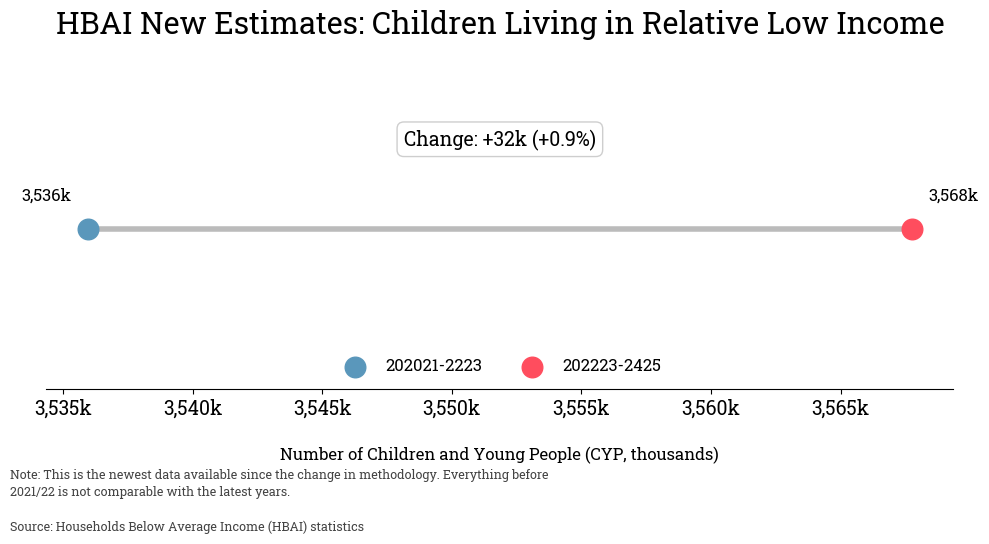

In [3]:
## Plotting indicators: Material deprivation and Poverty

plot_indicator_dumbbell(
    "CYPHPHARMPVT_2",
    year_filter=["202021-2223", "202223-2425"],
    df=df,
    title="HBAI New Estimates: Children Living in Relative Low Income",
    note="This is the newest data available since the change in methodology. Everything before 2021/22 is not comparable with the latest years.",
    figsize=(10, 5.5),
    save_path="CYPHPHARMPVT_2_dumbbell.png"
)


Summary calculations for CYPHPHARMPVT_1: CYP eligible for free school meals
Period: 2017/18 to 2024/25
Observations: 8

Start-to-end change
--------------------------------------------------------------------------------
Start value: 1,106,633
End value: 2,171,916
Absolute change: 1,065,283
Total percentage change: 96.3%
Average annual change (CAGR-style): 10.11% per year

Latest annual change
--------------------------------------------------------------------------------
Previous value: 2,094,169
Latest annual percentage change: +3.7%



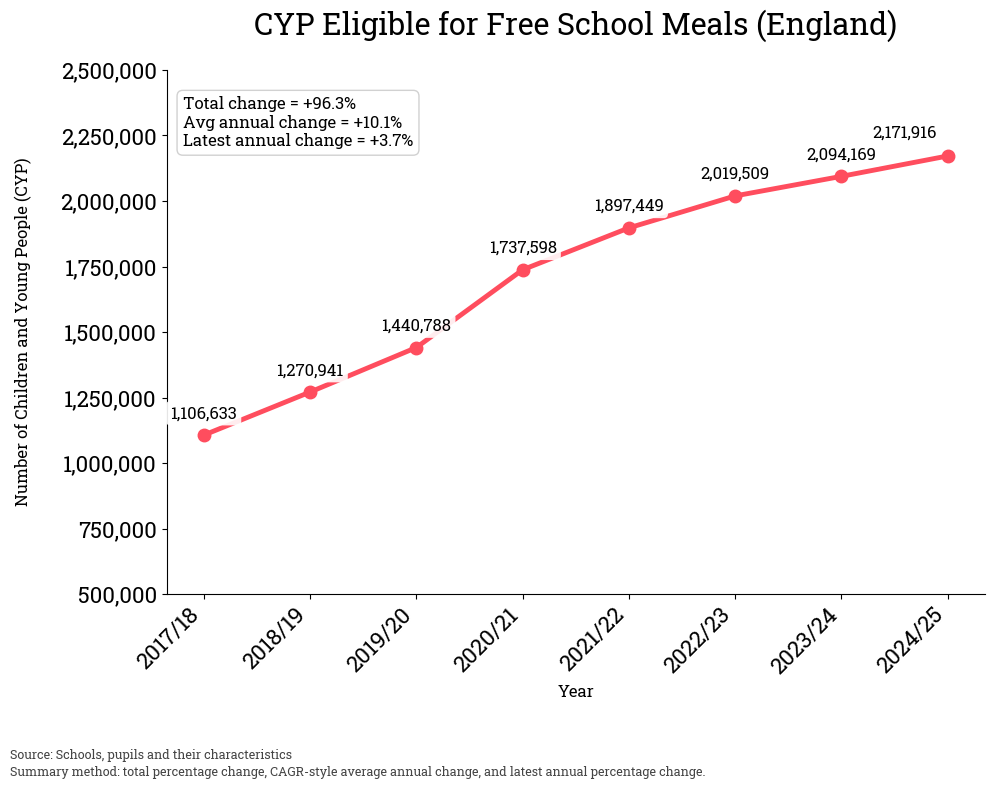

In [4]:
## Plotting indicators: Free school means

plot_indicator(
    "CYPHPHARMPVT_1",
    df=df,
    title="CYP Eligible for Free School Meals (England)",
    figsize=(10, 8),
    save_path="CYPHPHARMPVT_1.png"
)


Summary calculations for CYPHPHARMPVT_4: Percentage of children in food insecure homes
Period: 2021/22 to 2024/25
Observations: 4

Start-to-end change
--------------------------------------------------------------------------------
Start value: 11.4%
End value: 13.7%
Absolute change: +2.3 percentage points
Total percentage-point change: +2.3 percentage points
Average annual percentage-point change: +0.78 percentage points per year

Latest annual change
--------------------------------------------------------------------------------
Previous value: 18.0%
Latest annual percentage-point change: -4.2 pp



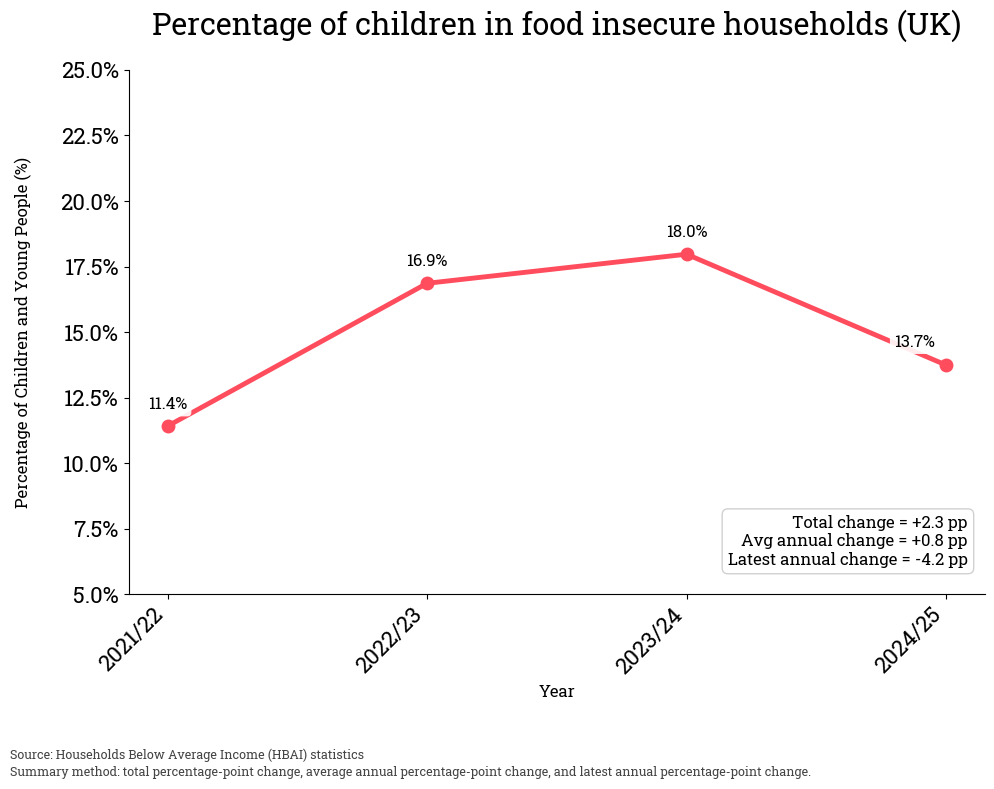

In [5]:
## Plotting indicators: Food insecurity

plot_indicator(
    "CYPHPHARMPVT_4",
    value_type="proportion",
    df=df,
    title="Percentage of children in food insecure households (UK)",
    figsize=(10, 8),
    save_path="CYPHPHARMPVT_4.png"
)


Summary calculations for CYPHPHARMPVT_3: CYP in destitution
Period: 2015 to 2022
Observations: 4

Start-to-end change
--------------------------------------------------------------------------------
Start value: 312,000
End value: 1,000,000
Absolute change: 688,000
Total percentage change: 220.5%
Average annual change (CAGR-style): 18.10% per year

Latest annual change
--------------------------------------------------------------------------------
Previous value: 550,000
Latest annual percentage change: +81.8%



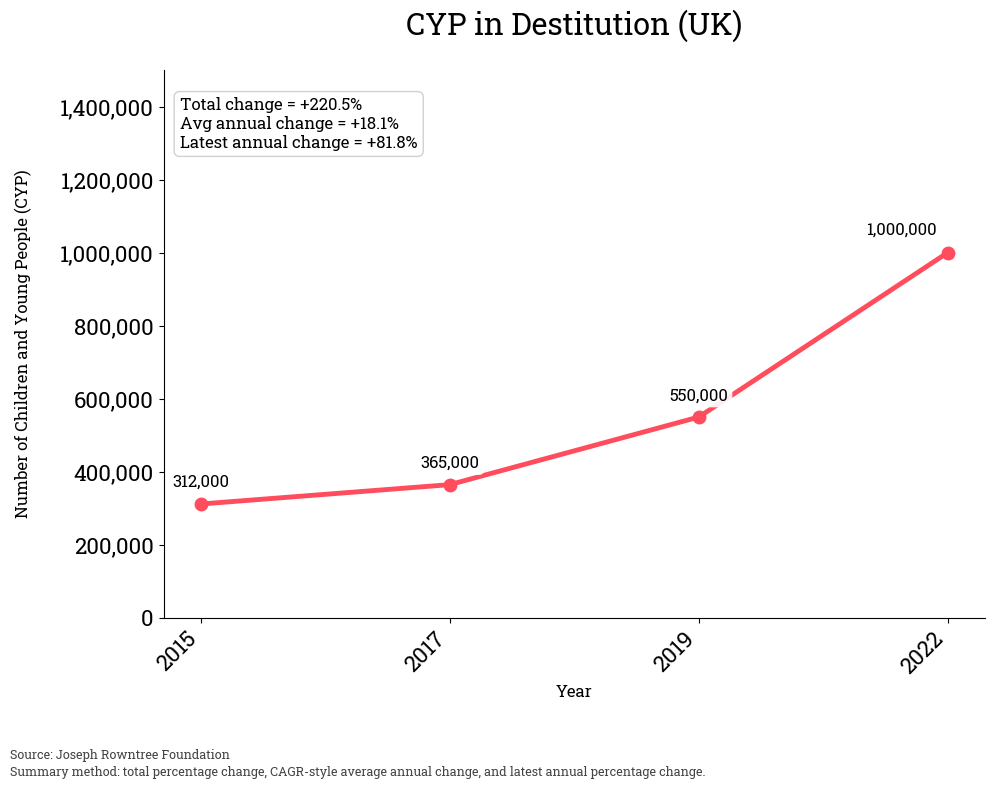

In [6]:
## Plotting indicators: CYP in destitution

plot_indicator(
    "CYPHPHARMPVT_3",
    df=df,
    title="CYP in Destitution (UK)",
    figsize=(10, 8),
    save_path="CYPHPHARMPVT_3.png"
)


Summary calculations for CYPHPHARMPVT_5: Number of children in food insecure homes
Period: 2021/22 to 2024/25
Observations: 4

Start-to-end change
--------------------------------------------------------------------------------
Start value: 1,648,231
End value: 2,013,652
Absolute change: 365,421
Total percentage change: 22.2%
Average annual change (CAGR-style): 6.90% per year

Latest annual change
--------------------------------------------------------------------------------
Previous value: 2,617,590
Latest annual percentage change: -23.1%



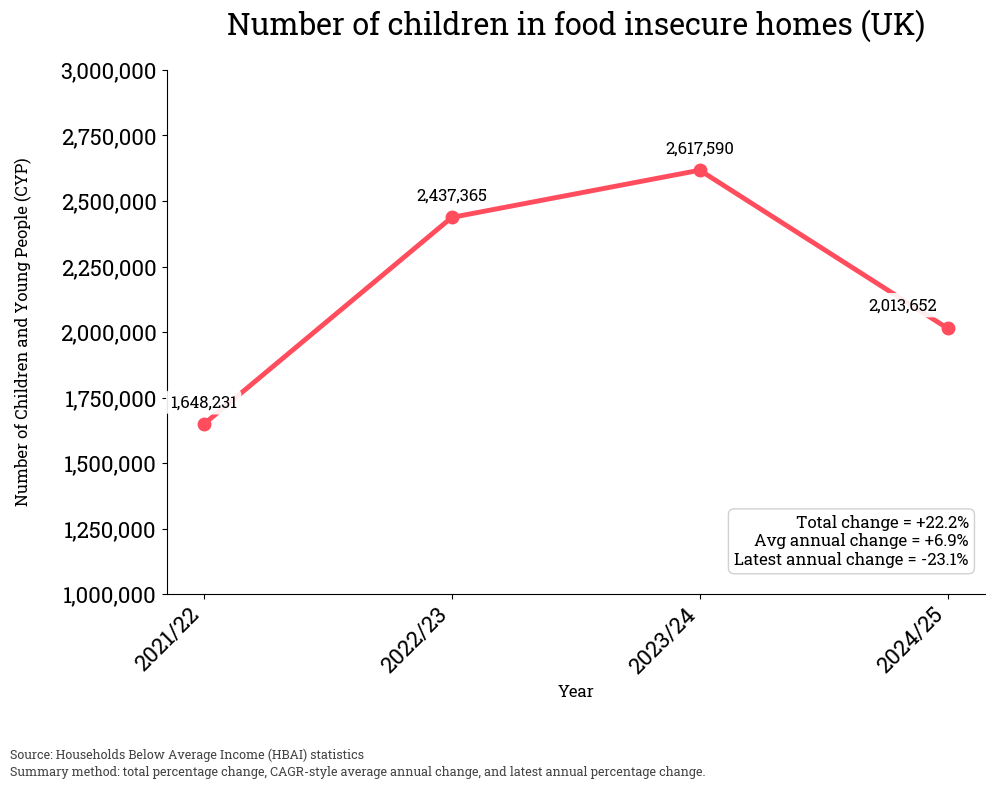

In [7]:
# Plotting indicators: Number of children in food insecure homes

plot_indicator(
    "CYPHPHARMPVT_5",
    df=df,
    title="Number of children in food insecure homes (UK)",
    figsize=(10, 8),
    save_path="CYPHPHARMPVT_5.png"
)

## Plotting indicators: Children facing homelessness


Summary calculations for CYPHPHARMHM&UH_1: CYP living in households in temporary accommodation
Period: 2018 to 2024
Observations: 7

Start-to-end change
--------------------------------------------------------------------------------
Start value: 124,330
End value: 165,450
Absolute change: 41,120
Total percentage change: 33.1%
Average annual change (CAGR-style): 4.88% per year

Latest annual change
--------------------------------------------------------------------------------
Previous value: 145,780
Latest annual percentage change: +13.5%



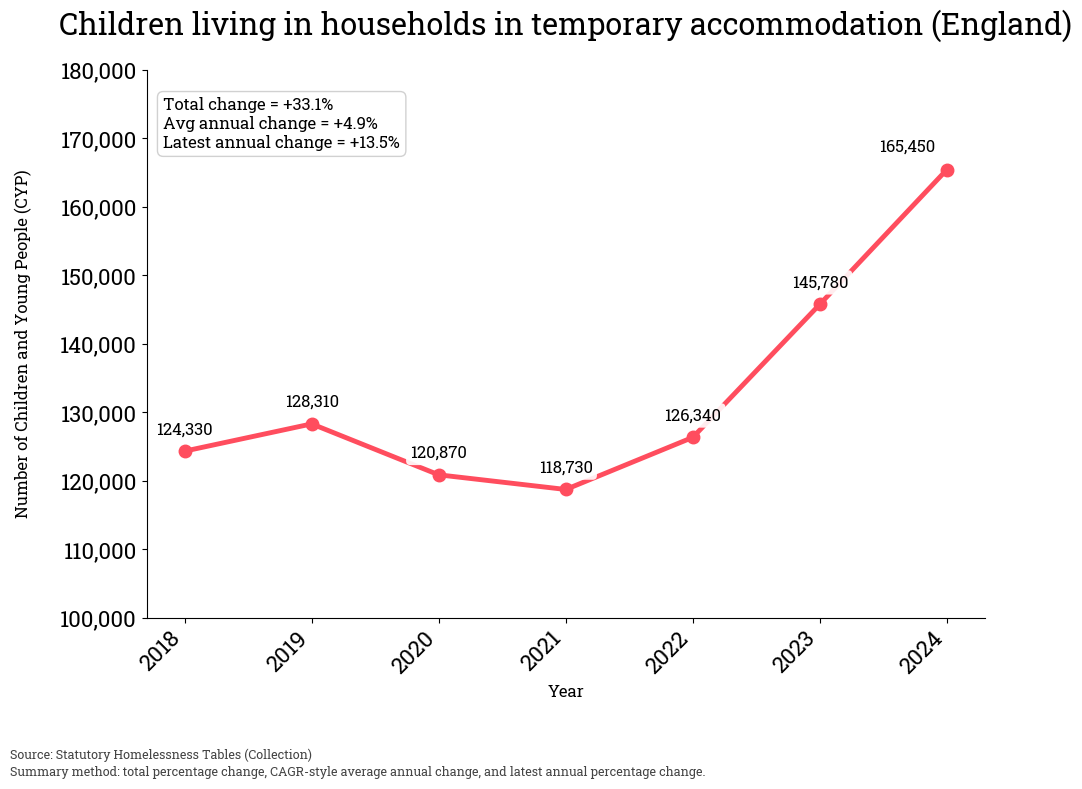

In [8]:
## Plotting indicators: CYP living in temporary accommodations

plot_indicator(
    "CYPHPHARMHM&UH_1",
    df=df,
    title="Children living in households in temporary accommodation (England)",
    figsize=(10, 8),
    save_path="CYPHPHARMHM&UH_1.png"
)


Summary calculations for CYPHPHARMHM&UH_3: Homeless households with children
Period: 2018/19 to 2024/25
Observations: 7

Start-to-end change
--------------------------------------------------------------------------------
Start value: 29,200
End value: 47,460
Absolute change: 18,260
Total percentage change: 62.5%
Average annual change (CAGR-style): 8.43% per year

Latest annual change
--------------------------------------------------------------------------------
Previous value: 47,740
Latest annual percentage change: -0.6%



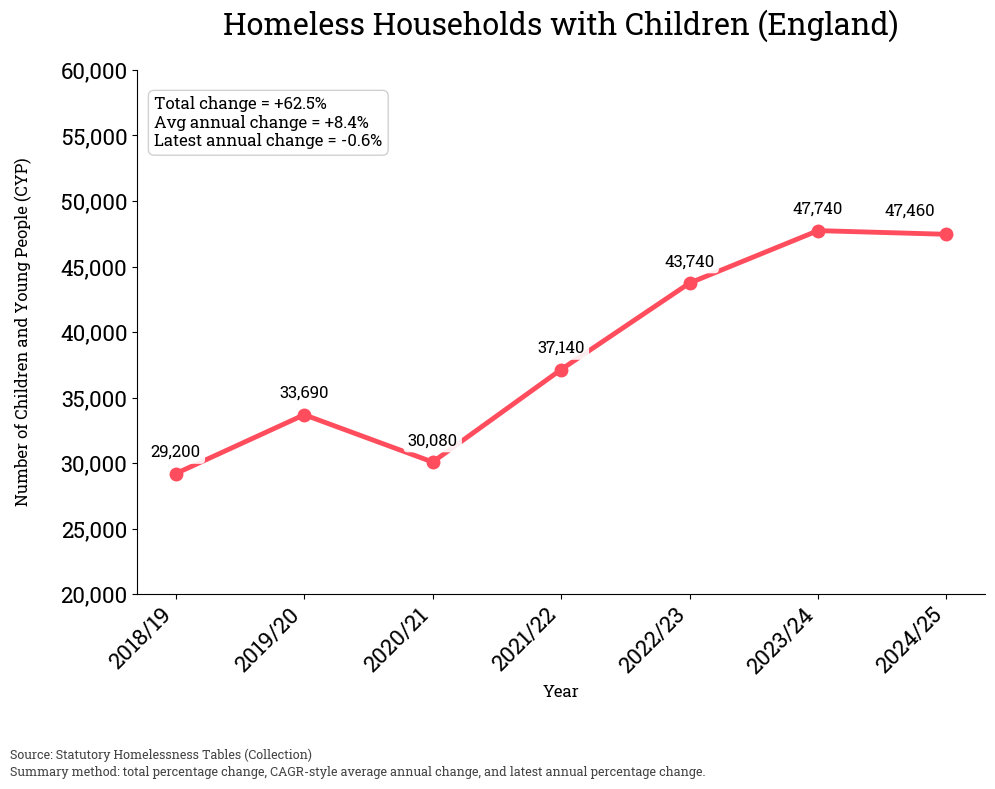

In [9]:
## Plotting indicators: Homeless households with children

plot_indicator(
    "CYPHPHARMHM&UH_3",
    df=df,
    title="Homeless Households with Children (England)",
    figsize=(10, 8),
    save_path="CYPHPHARMHM&UH_3.png"
)


Summary calculations for CYPHPHARMHM&UH_2: CYP aged 16-24 assessed as owed a prevention or relief duty
Period: 2018/19 to 2024/25
Observations: 7

Start-to-end change
--------------------------------------------------------------------------------
Start value: 57,690
End value: 58,510
Absolute change: 820
Total percentage change: 1.4%
Average annual change (CAGR-style): 0.24% per year

Latest annual change
--------------------------------------------------------------------------------
Previous value: 59,310
Latest annual percentage change: -1.3%



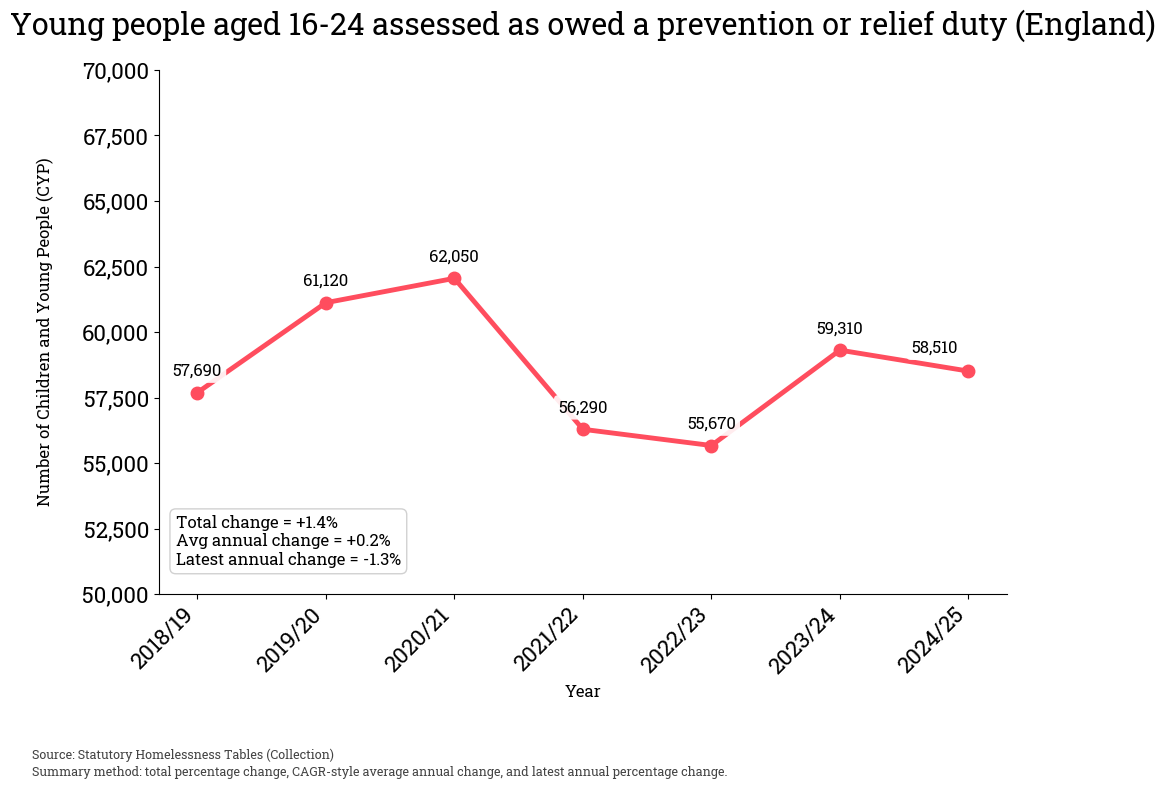

In [10]:
## Plotting indicators: CYP aged 16-24 assessed as owed a prevention or relief duty

plot_indicator(
    "CYPHPHARMHM&UH_2",
    df=df,
    title="Young people aged 16-24 assessed as owed a prevention or relief duty (England)",
    figsize=(10, 8),
    save_path="CYPHPHARMHM&UH_2.png"
)

## Plotting indicators: Children in need


Summary calculations for CYPSCCiN: Children in need at 31st March (excluding unborn children)
Period: 2018 to 2025
Observations: 8

Start-to-end change
--------------------------------------------------------------------------------
Start value: 397,430
End value: 395,270
Absolute change: -2,160
Total percentage change: -0.5%
Average annual change (CAGR-style): -0.08% per year

Latest annual change
--------------------------------------------------------------------------------
Previous value: 392,680
Latest annual percentage change: +0.7%



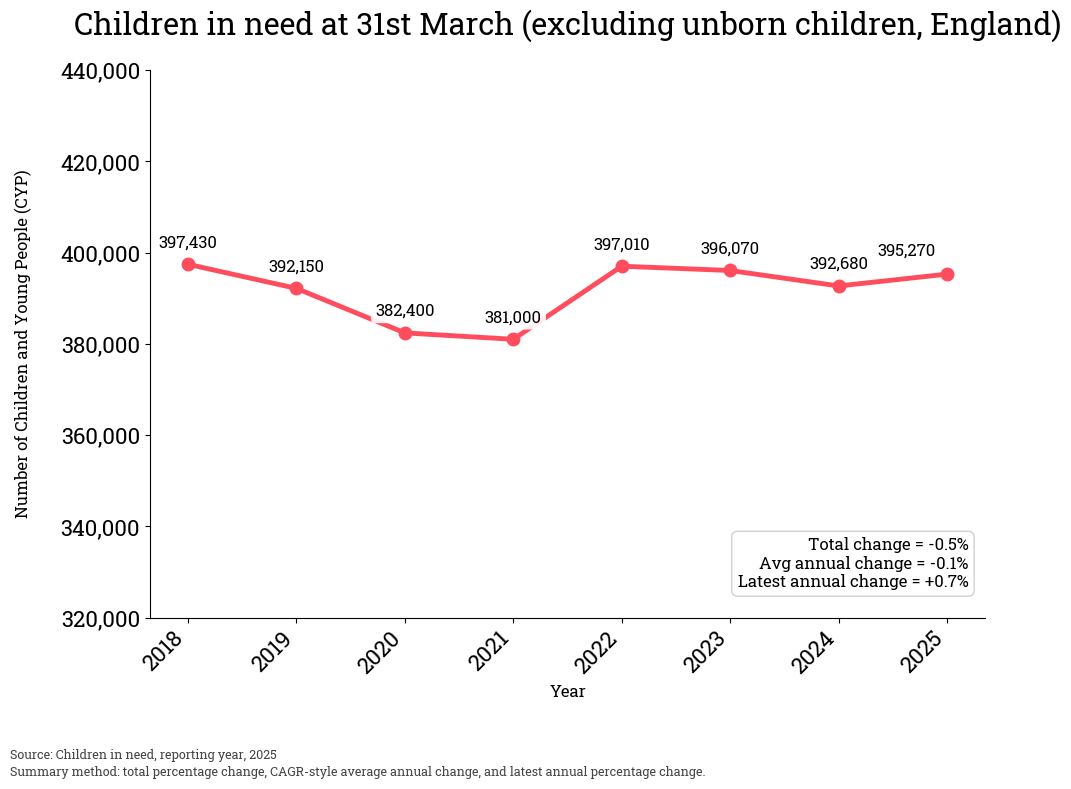

In [11]:
## Plotting indicators: Children in need

plot_indicator(
    "CYPSCCiN",
    df=df,
    title="Children in need at 31st March (excluding unborn children, England)",
    figsize=(10, 8),
    save_path="CYPSCCiN.png"
)


Summary calculations for CYPSCCPP: CYP who were the subject of a CPP at the end of the year
Period: 2018 to 2025
Observations: 8

Start-to-end change
--------------------------------------------------------------------------------
Start value: 53,790
End value: 49,420
Absolute change: -4,370
Total percentage change: -8.1%
Average annual change (CAGR-style): -1.20% per year

Latest annual change
--------------------------------------------------------------------------------
Previous value: 49,900
Latest annual percentage change: -1.0%



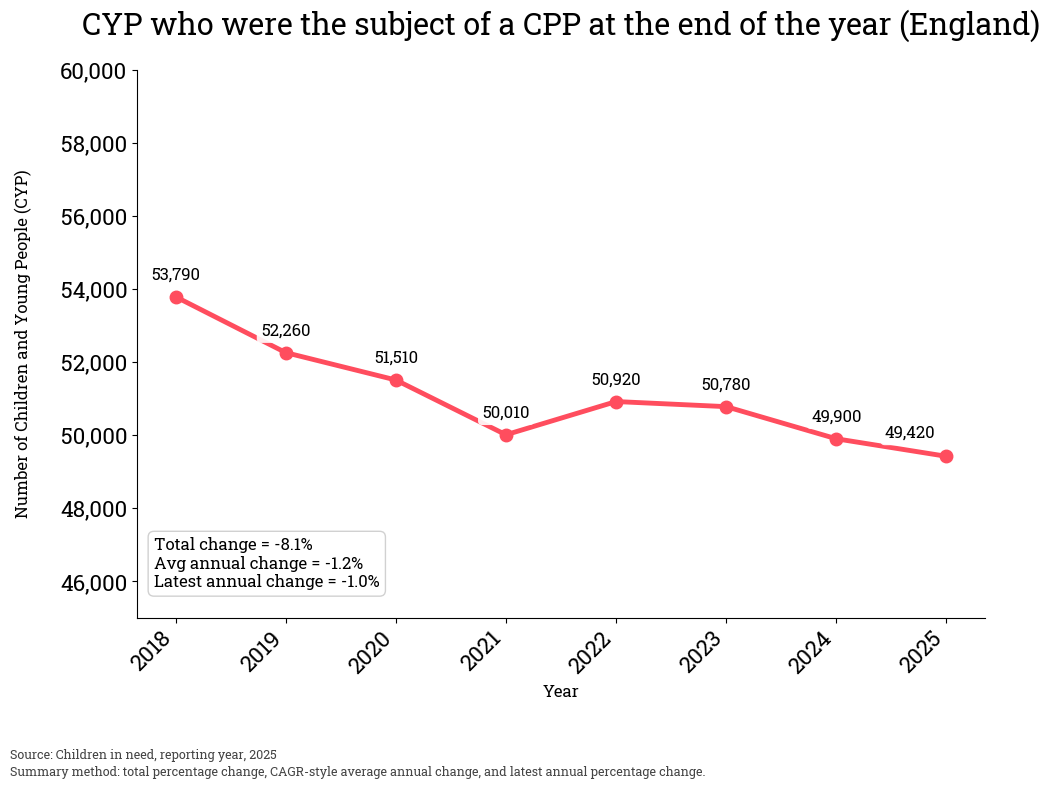

In [12]:
## Plotting indicators: Child Protection Plans

plot_indicator(
    "CYPSCCPP",
    df=df,
    title="CYP who were the subject of a CPP at the end of the year (England)",
    figsize=(10, 8),
    save_path="CYPSCCPP.png"
)


Summary calculations for CYPHPHARMNiN_2: CYP with No Further Action referrals
Period: 2018 to 2025
Observations: 8

Start-to-end change
--------------------------------------------------------------------------------
Start value: 61,690
End value: 41,340
Absolute change: -20,350
Total percentage change: -33.0%
Average annual change (CAGR-style): -5.56% per year

Latest annual change
--------------------------------------------------------------------------------
Previous value: 38,920
Latest annual percentage change: +6.2%



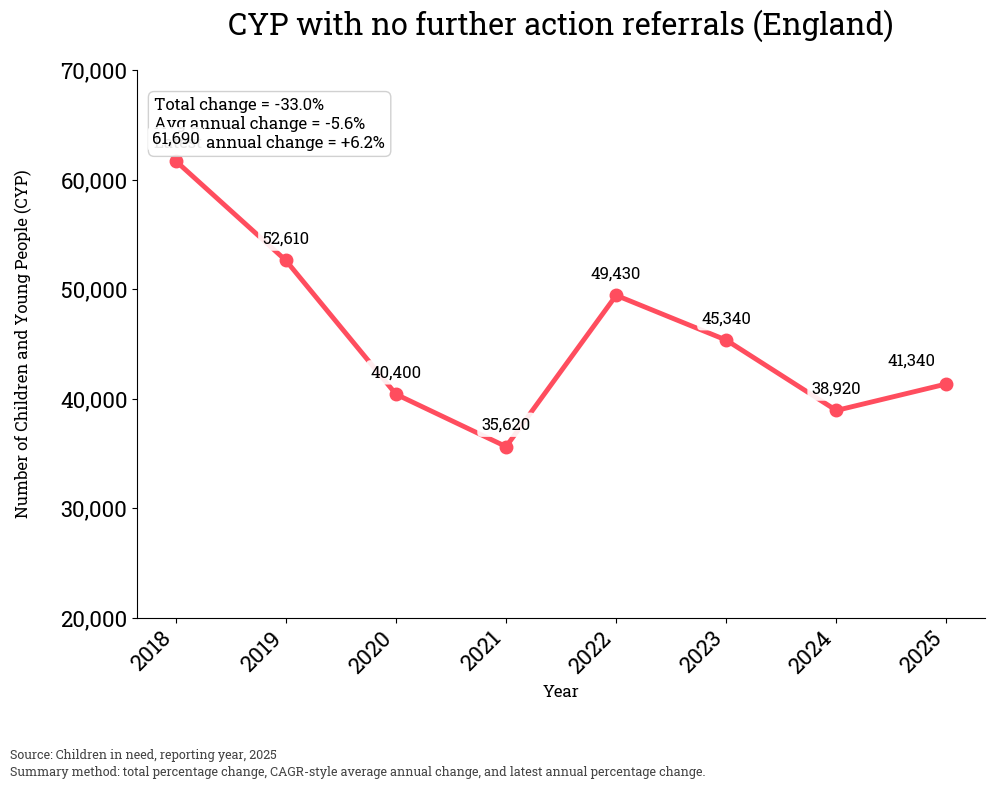

In [13]:
## Plotting indicators: No Further Action Referrals

plot_indicator(
    "CYPHPHARMNiN_2",
    df=df,
    title="CYP with no further action referrals (England)",
    figsize=(10, 8),
    save_path="CYPHPHARMNiN_2.png"
)


Summary calculations for CYPHPHARMNiN_1: CYP who were assessed as Not in Need (NiN)
Period: 2017 to 2025
Observations: 9

Start-to-end change
--------------------------------------------------------------------------------
Start value: 179,930
End value: 194,620
Absolute change: 14,690
Total percentage change: 8.2%
Average annual change (CAGR-style): 0.99% per year

Latest annual change
--------------------------------------------------------------------------------
Previous value: 188,300
Latest annual percentage change: +3.4%



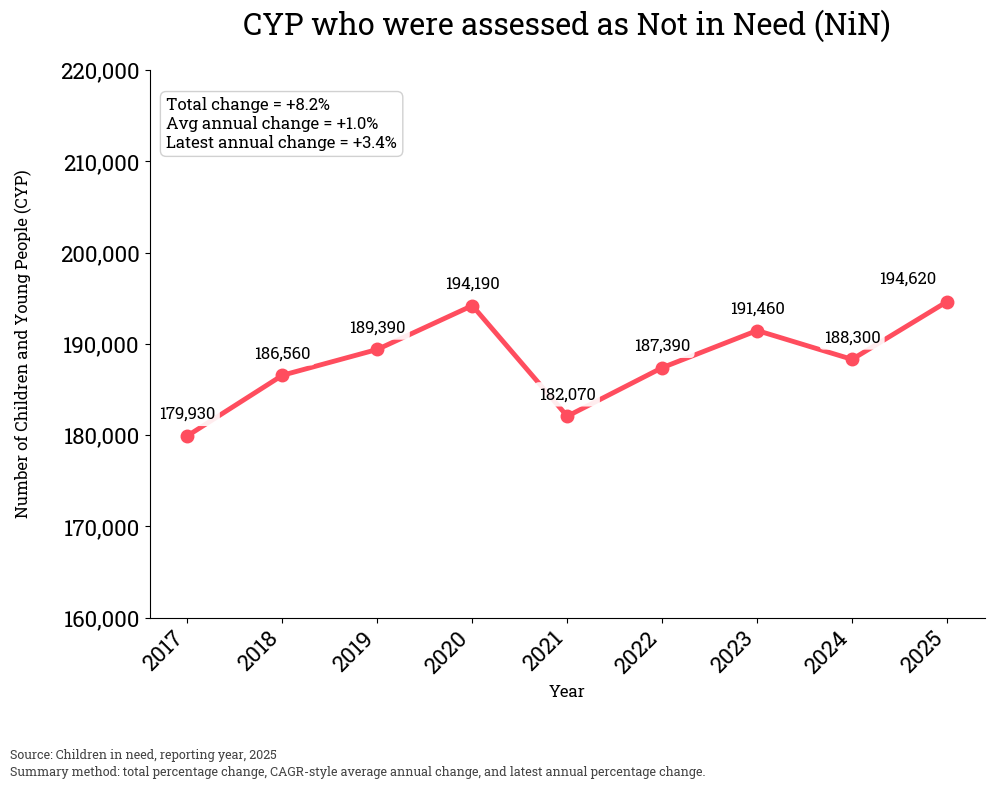

In [14]:
## Plotting indicators: Children not in need

plot_indicator(
    "CYPHPHARMNiN_1",
    df=df,
    title="CYP who were assessed as Not in Need (NiN)",
    figsize=(10, 8),
    save_path="CYPHPHARMNiN_1.png"
)

## Plotting indicators: Children Looked After


Summary calculations for CYPSCLA_1: Children looked after on 31 March
Period: 2018 to 2025
Observations: 8

Start-to-end change
--------------------------------------------------------------------------------
Start value: 75,360
End value: 81,770
Absolute change: 6,410
Total percentage change: 8.5%
Average annual change (CAGR-style): 1.17% per year

Latest annual change
--------------------------------------------------------------------------------
Previous value: 83,530
Latest annual percentage change: -2.1%



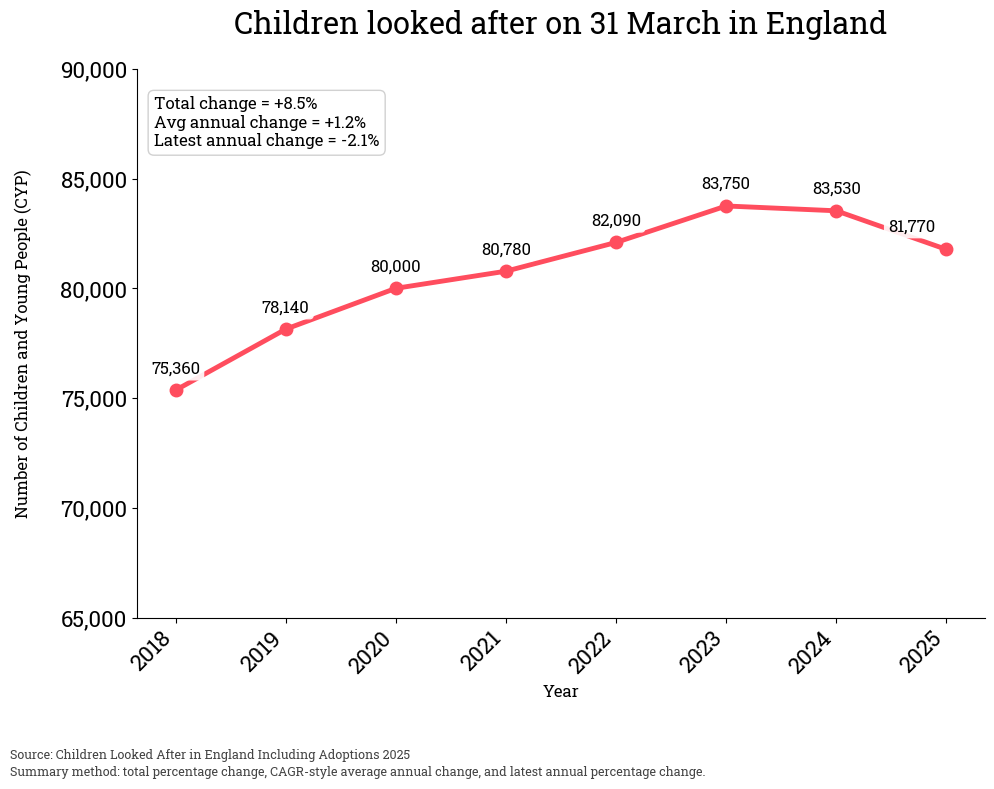

In [15]:
## Plotting indicators: Children Looked After

plot_indicator(
    "CYPSCLA_1",
    df=df,
    title="Children looked after on 31 March in England",
    figsize=(10, 8),
    save_path="CYPSCLA_1.png"
)


Summary calculations for CYPSCLA_12: CYP aged 16+ entering care
Period: 2021 to 2025
Observations: 5

Start-to-end change
--------------------------------------------------------------------------------
Start value: 5,710
End value: 9,110
Absolute change: 3,400
Total percentage change: 59.5%
Average annual change (CAGR-style): 12.39% per year

Latest annual change
--------------------------------------------------------------------------------
Previous value: 9,440
Latest annual percentage change: -3.5%



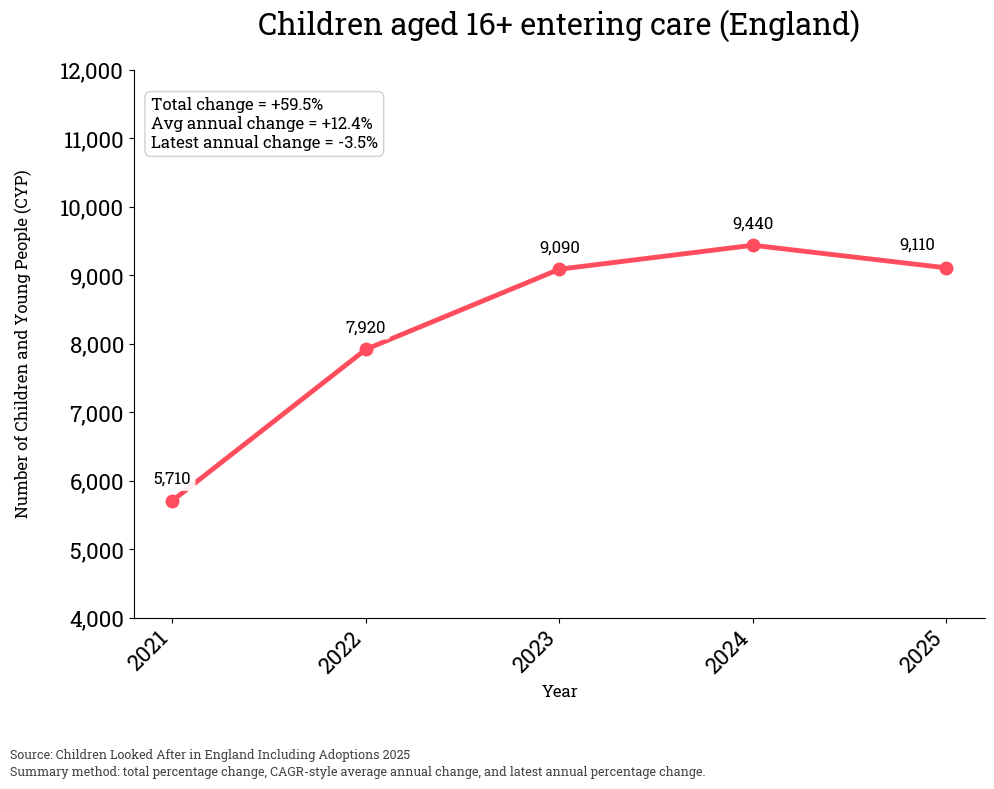

In [16]:
## Children looked after who are 16+

plot_indicator(
    "CYPSCLA_12",
    df=df,
    title="Children aged 16+ entering care (England)",
    figsize=(10, 8),
    save_path="CYPSCLA_12.png"
)


Summary calculations for CYPHPHARMHM&UH_4: CYP in confirmed Unregistered Childrens Homes (UCH)
Period: 2020/21 to 2023/24
Observations: 4

Start-to-end change
--------------------------------------------------------------------------------
Start value: 147
End value: 982
Absolute change: 835
Total percentage change: 568.0%
Average annual change (CAGR-style): 88.34% per year

Latest annual change
--------------------------------------------------------------------------------
Previous value: 724
Latest annual percentage change: +35.6%



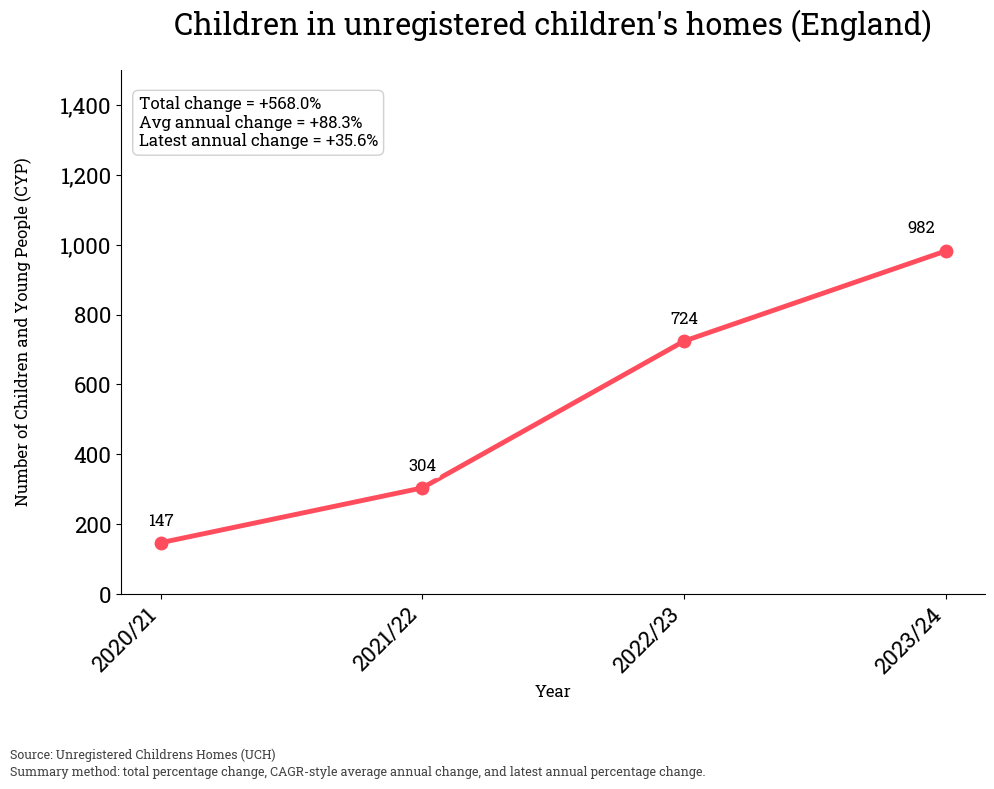

In [17]:
## Children in confirmed Unregistered Children's Homes

plot_indicator(
    "CYPHPHARMHM&UH_4",
    df=df,
    title="Children in unregistered children's homes (England)",
    figsize=(10, 8),
    save_path="CYPHPHARMHM&UH_4.png"
)

## Plotting indicators: Children from families with vulnerabilities


Summary calculations for CYPHPHARMDA_2: CYP in households that report domestic abuse (parent is victim)
Period: 2018 to 2025
Observations: 8

Start-to-end change
--------------------------------------------------------------------------------
Start value: 155,420
End value: 162,890
Absolute change: 7,470
Total percentage change: 4.8%
Average annual change (CAGR-style): 0.67% per year

Latest annual change
--------------------------------------------------------------------------------
Previous value: 160,600
Latest annual percentage change: +1.4%



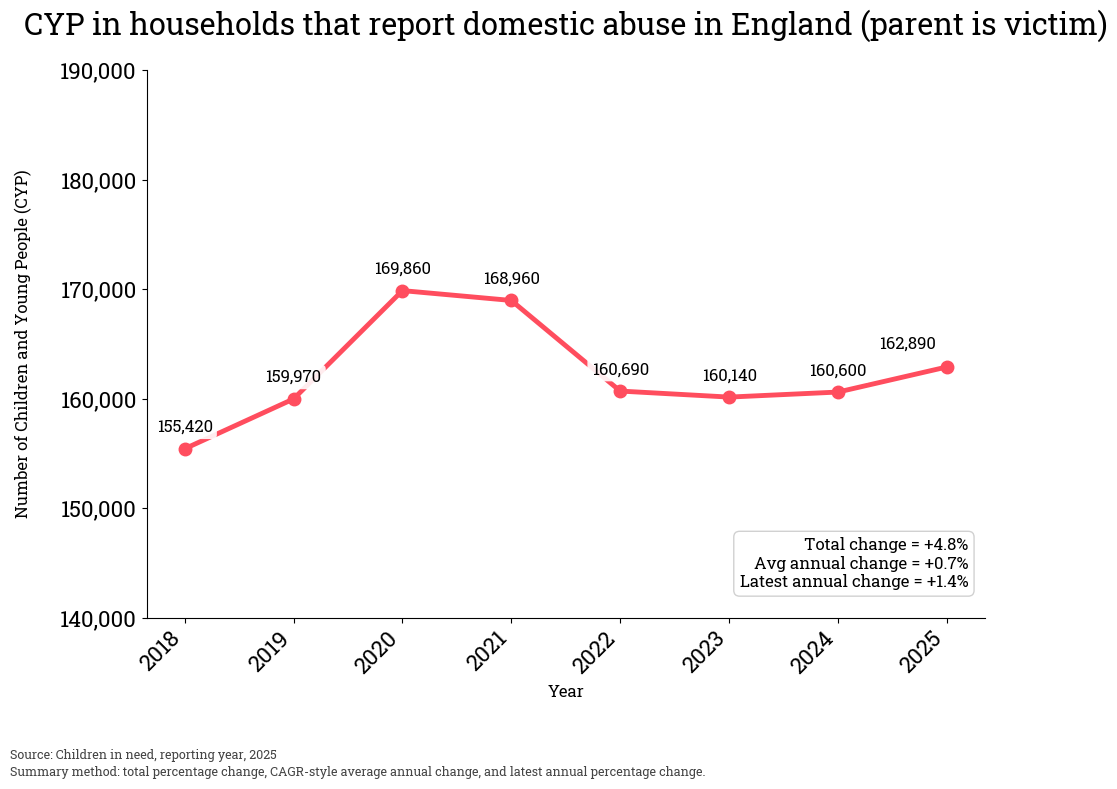

In [18]:
## Plotting indicators: CYP in households that report domestic abuse in England (parent is victim)

plot_indicator(
    "CYPHPHARMDA_2",
    df=df,
    title="CYP in households that report domestic abuse in England (parent is victim)",
    figsize=(10, 8),
    save_path="CYPHPHARMDA_2.png"
)


Summary calculations for CYPHPHARMDA_1: CYP in households that report domestic abuse (child is victim)
Period: 2018 to 2025
Observations: 8

Start-to-end change
--------------------------------------------------------------------------------
Start value: 61,650
End value: 57,930
Absolute change: -3,720
Total percentage change: -6.0%
Average annual change (CAGR-style): -0.89% per year

Latest annual change
--------------------------------------------------------------------------------
Previous value: 55,040
Latest annual percentage change: +5.3%



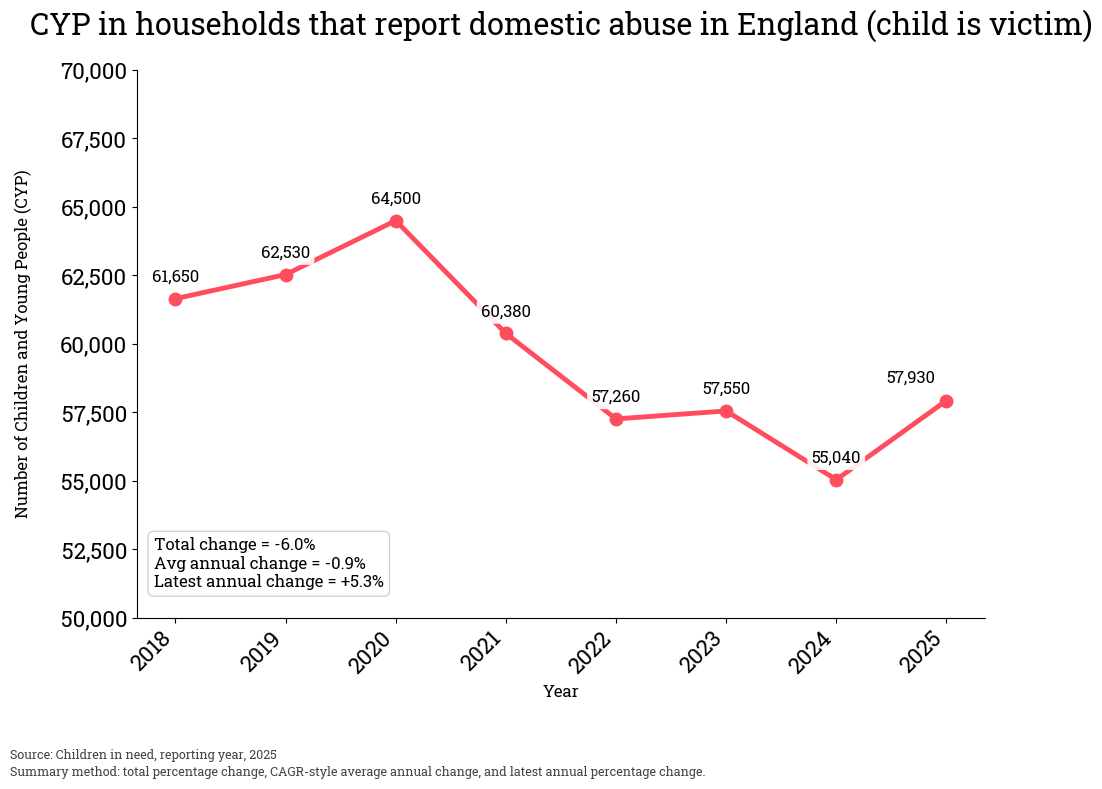

In [19]:
## Plotting indicators: CYP in households that report domestic abuse (child is victim)

plot_indicator(
    "CYPHPHARMDA_1",
    df=df,
    title="CYP in households that report domestic abuse in England (child is victim)",
    figsize=(10, 8),
    save_path="CYPHPHARMDA_1.png"
)


Summary calculations for CYPHPHARMSUB_1: CYP in households with alcohol dependency (by the parent)
Period: 2018 to 2025
Observations: 8

Start-to-end change
--------------------------------------------------------------------------------
Start value: 64,380
End value: 73,250
Absolute change: 8,870
Total percentage change: 13.8%
Average annual change (CAGR-style): 1.86% per year

Latest annual change
--------------------------------------------------------------------------------
Previous value: 72,410
Latest annual percentage change: +1.2%



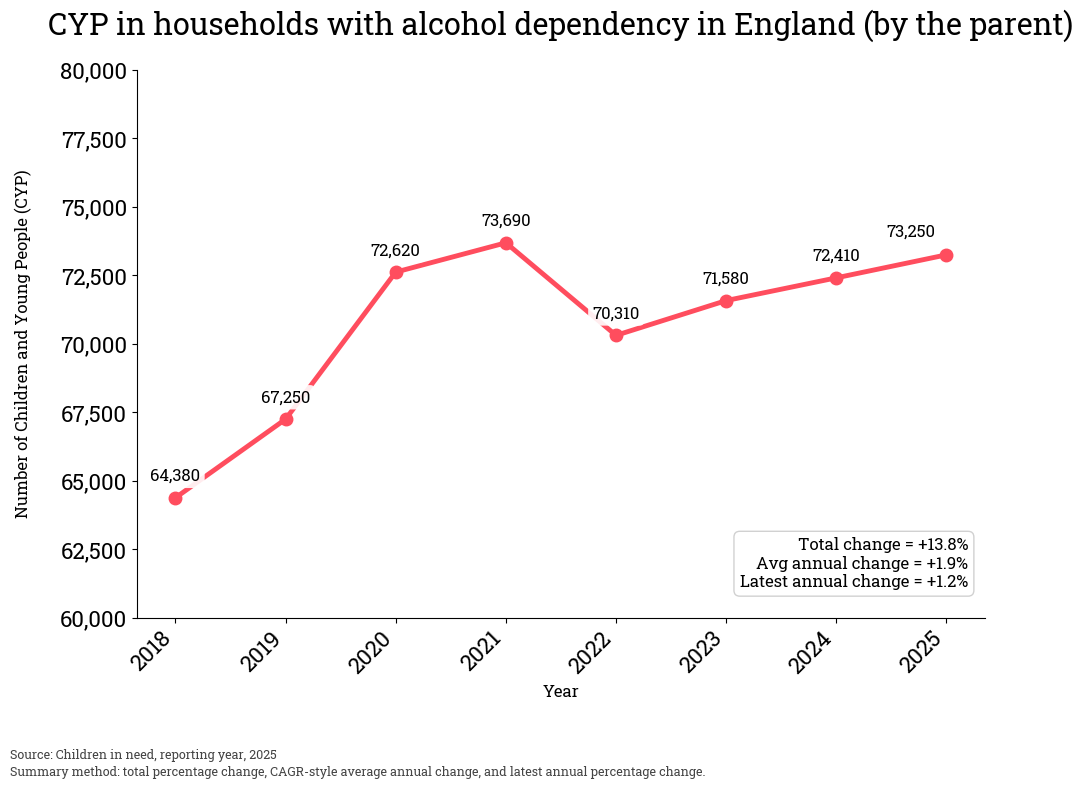

In [20]:
## Plotting indicators: CYP in households with alcohol dependency in England (by the parent)

plot_indicator(
    "CYPHPHARMSUB_1",
    df=df,
    title="CYP in households with alcohol dependency in England (by the parent)",
    figsize=(10, 8),
    save_path="CYPHPHARMSUB_1.png"
)


Summary calculations for CYPDISAUNHB_2: CYP in households with alcohol dependency (by the child)
Period: 2018 to 2025
Observations: 8

Start-to-end change
--------------------------------------------------------------------------------
Start value: 12,800
End value: 10,620
Absolute change: -2,180
Total percentage change: -17.0%
Average annual change (CAGR-style): -2.63% per year

Latest annual change
--------------------------------------------------------------------------------
Previous value: 10,770
Latest annual percentage change: -1.4%



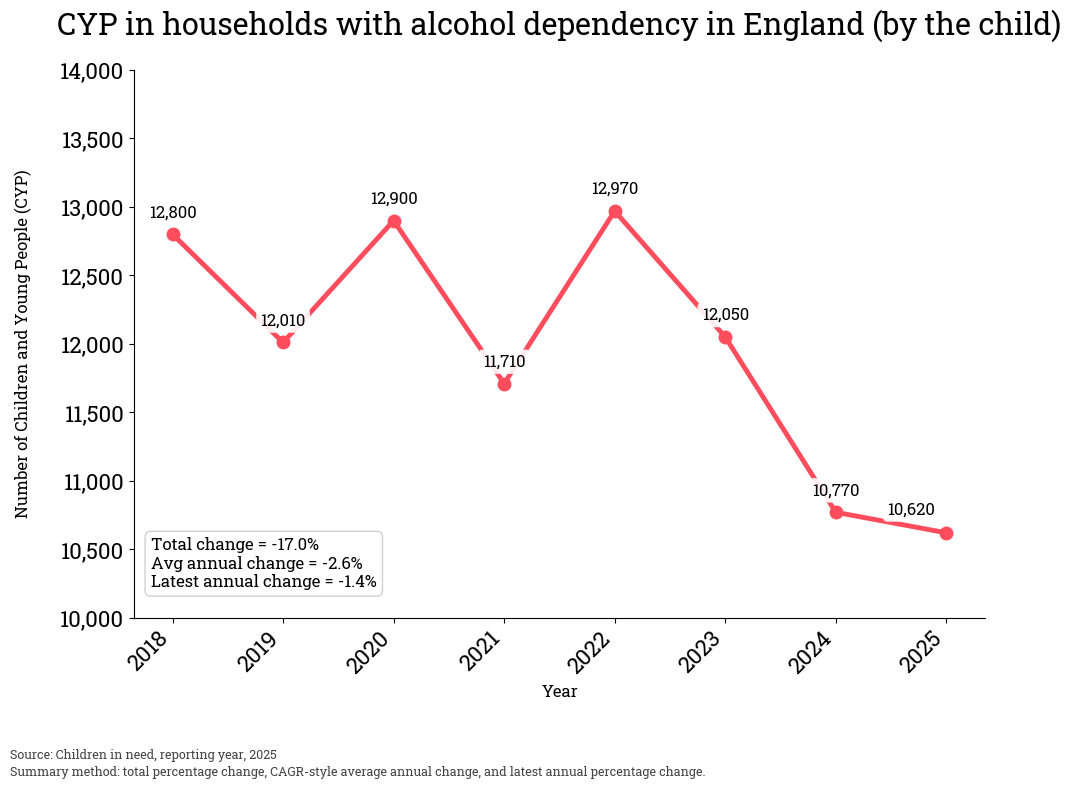

In [21]:
## Plotting indicators: CYP in households with alcohol dependency in England (by the child)

plot_indicator(
    "CYPDISAUNHB_2",
    df=df,
    title="CYP in households with alcohol dependency in England (by the child)",
    figsize=(10, 8),
    save_path="CYPDISAUNHB_2.png"
)


Summary calculations for CYPHPHARMSUB_2: CYP in households with drug dependency (by the parent)
Period: 2018 to 2025
Observations: 8

Start-to-end change
--------------------------------------------------------------------------------
Start value: 62,260
End value: 72,620
Absolute change: 10,360
Total percentage change: 16.6%
Average annual change (CAGR-style): 2.22% per year

Latest annual change
--------------------------------------------------------------------------------
Previous value: 70,940
Latest annual percentage change: +2.4%



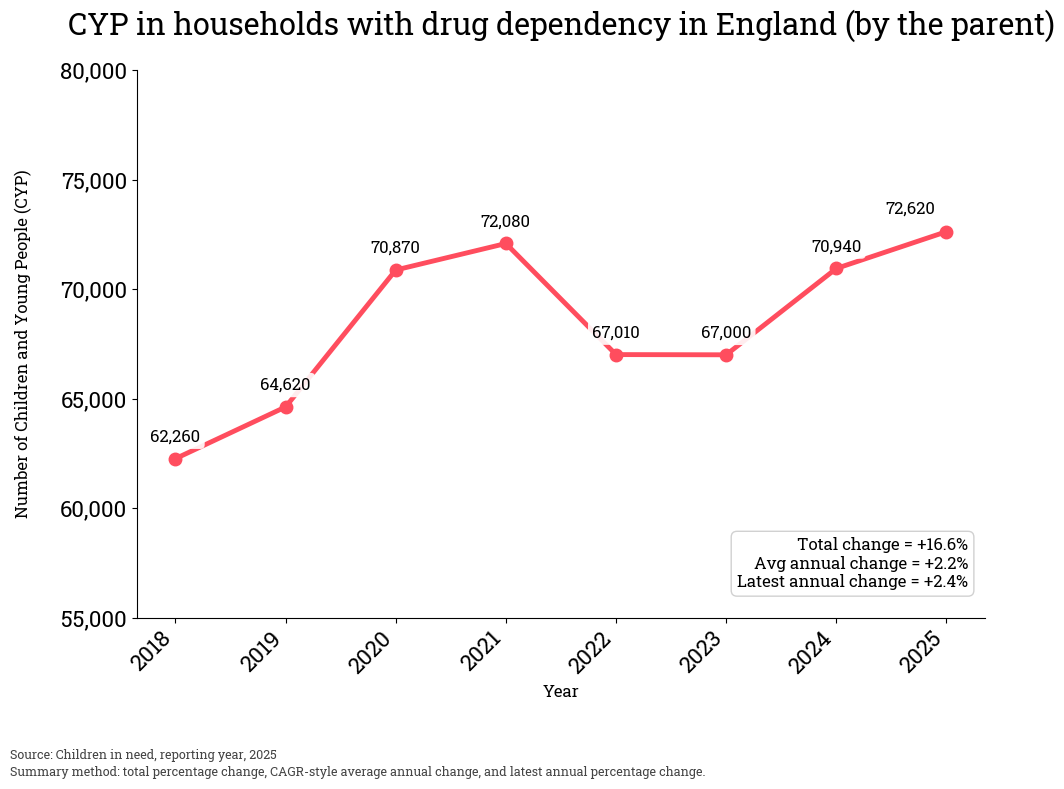

In [22]:
## Drug abuse by the parent

plot_indicator(
    "CYPHPHARMSUB_2",
    df=df,
    title="CYP in households with drug dependency in England (by the parent)",
    figsize=(10, 8),
    save_path="CYPHPHARMSUB_2.png"
)


Summary calculations for CYPDISAUNHB_3: CYP in households with drug dependency (by the child)
Period: 2018 to 2025
Observations: 8

Start-to-end change
--------------------------------------------------------------------------------
Start value: 23,190
End value: 24,550
Absolute change: 1,360
Total percentage change: 5.9%
Average annual change (CAGR-style): 0.82% per year

Latest annual change
--------------------------------------------------------------------------------
Previous value: 25,190
Latest annual percentage change: -2.5%



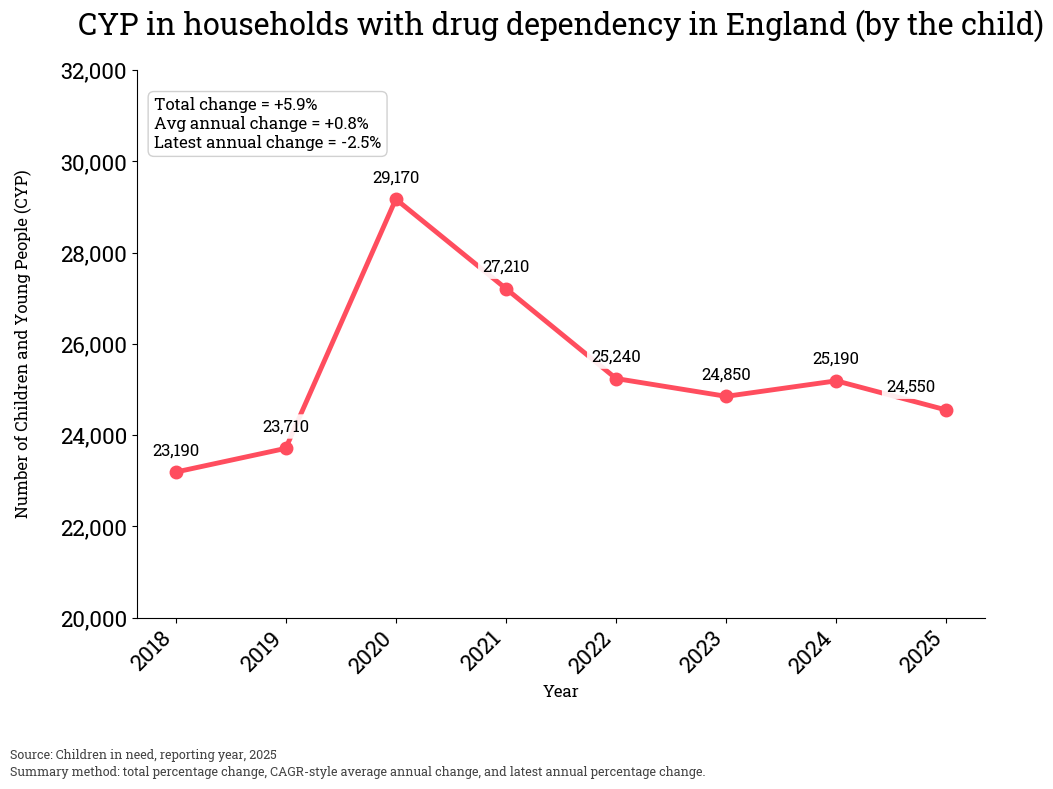

In [23]:
## Drud abuse by the child

plot_indicator(
    "CYPDISAUNHB_3",
    df=df,
    title="CYP in households with drug dependency in England (by the child)",
    figsize=(10, 8),
    save_path="CYPDISAUNHB_3.png"
)

# Plotting indicators: Children who are Victim of Crime, Exploitation, Violence and Abuse


Summary calculations for CYPSPHVoM_8: CYP who have been victims of criminal exploitation
Period: 2022 to 2025
Observations: 4

Start-to-end change
--------------------------------------------------------------------------------
Start value: 10,140
End value: 16,250
Absolute change: 6,110
Total percentage change: 60.3%
Average annual change (CAGR-style): 17.02% per year

Latest annual change
--------------------------------------------------------------------------------
Previous value: 15,750
Latest annual percentage change: +3.2%



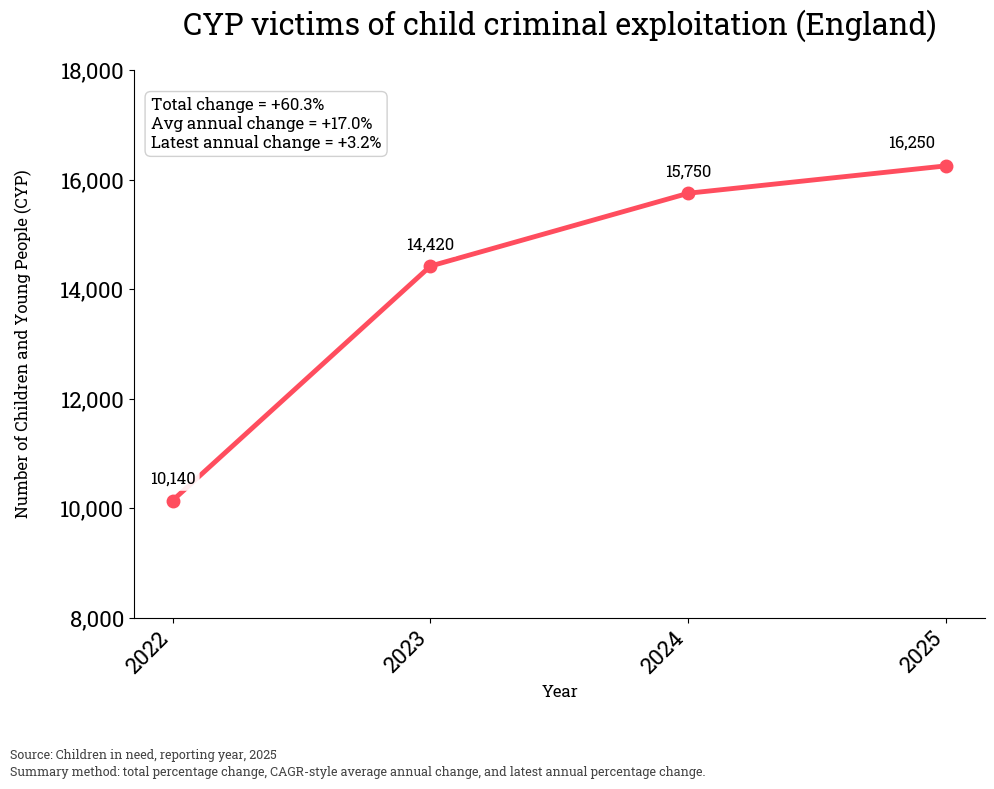

In [24]:
# Plotting indicators: Child Criminal Exploitation CiN data

plot_indicator(
    "CYPSPHVoM_8",
    df=df,
    title="CYP victims of child criminal exploitation (England)",
    figsize=(10, 8),
    save_path="CYPSPHVoM_8.png"
)


Summary calculations for CYPSPHVoM_2: CYP referred to the National Referral Mechanism (non-sexual exploitation, modern slavery)
Period: 2019 to 2025
Observations: 7

Start-to-end change
--------------------------------------------------------------------------------
Start value: 623
End value: 3,088
Absolute change: 2,465
Total percentage change: 395.7%
Average annual change (CAGR-style): 30.58% per year

Latest annual change
--------------------------------------------------------------------------------
Previous value: 2,613
Latest annual percentage change: +18.2%



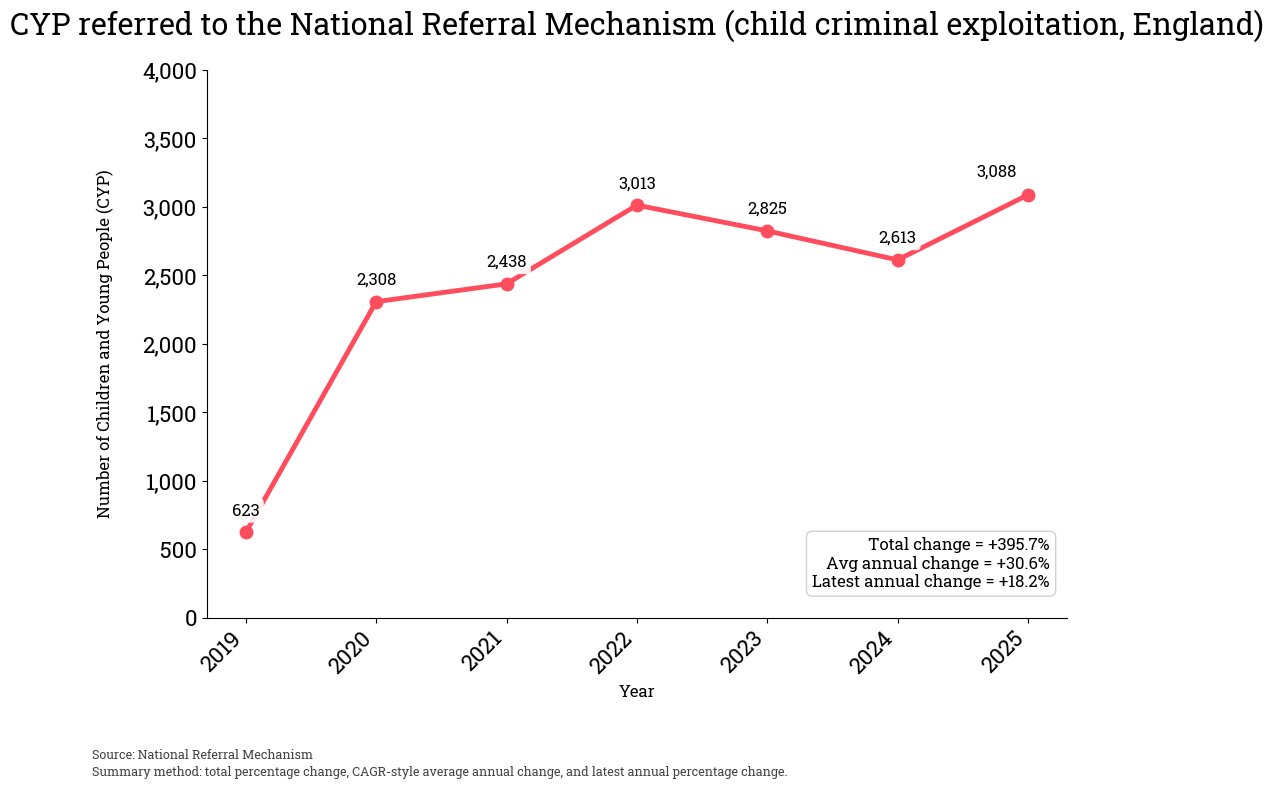

In [25]:
# Plotting indicators: Child Criminal Exploitation NRM data

plot_indicator(
    "CYPSPHVoM_2",
    df=df,
    title="CYP referred to the National Referral Mechanism (child criminal exploitation, England)",
    figsize=(10, 8),
    save_path="CYPSPHVoM_2.png"
)


Summary calculations for CYPSPHVoM_1: CYP victims of contact sexual abuse
Period: 2018 to 2025
Observations: 8

Start-to-end change
--------------------------------------------------------------------------------
Start value: 30,350
End value: 29,560
Absolute change: -790
Total percentage change: -2.6%
Average annual change (CAGR-style): -0.38% per year

Latest annual change
--------------------------------------------------------------------------------
Previous value: 29,070
Latest annual percentage change: +1.7%



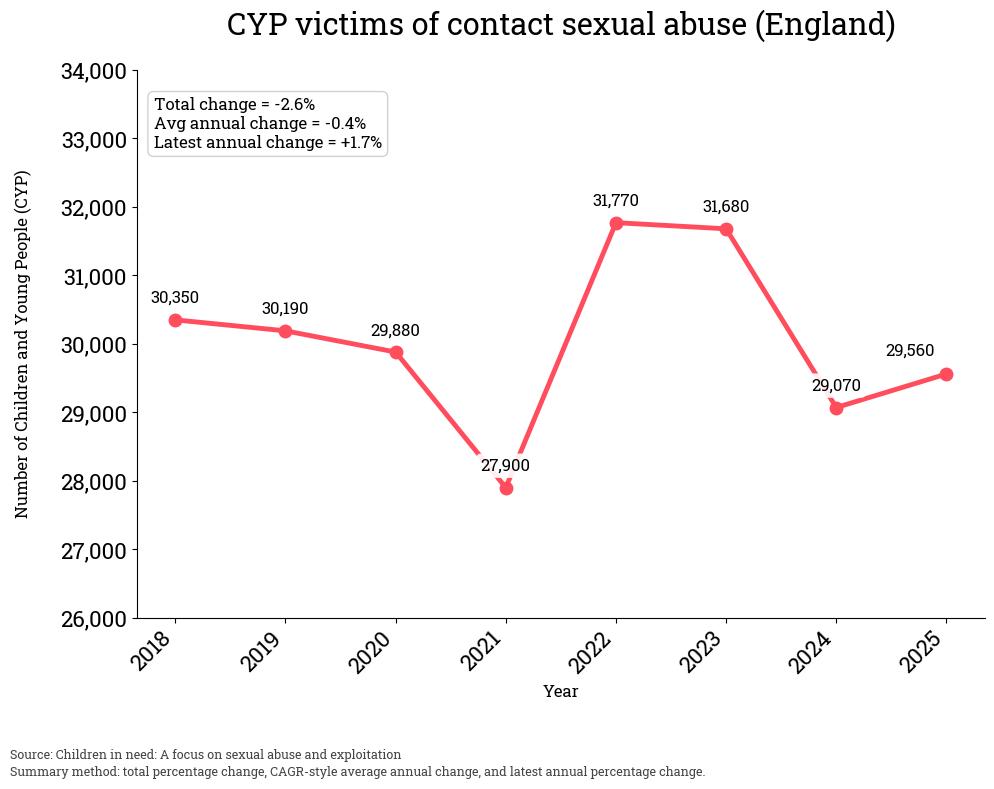

In [26]:
# Plotting indicators: Children victim of sexual abuse

plot_indicator(
    "CYPSPHVoM_1",
    df=df,
    title="CYP victims of contact sexual abuse (England)",
    figsize=(10, 8),
    save_path="CYPSPHVoM_1.png"
)


Summary calculations for CYPSPHVoM_9: CYP victims of child sexual exploitation
Period: 2017 to 2025
Observations: 9

Start-to-end change
--------------------------------------------------------------------------------
Start value: 18,270
End value: 12,120
Absolute change: -6,150
Total percentage change: -33.7%
Average annual change (CAGR-style): -5.00% per year

Latest annual change
--------------------------------------------------------------------------------
Previous value: 13,430
Latest annual percentage change: -9.8%



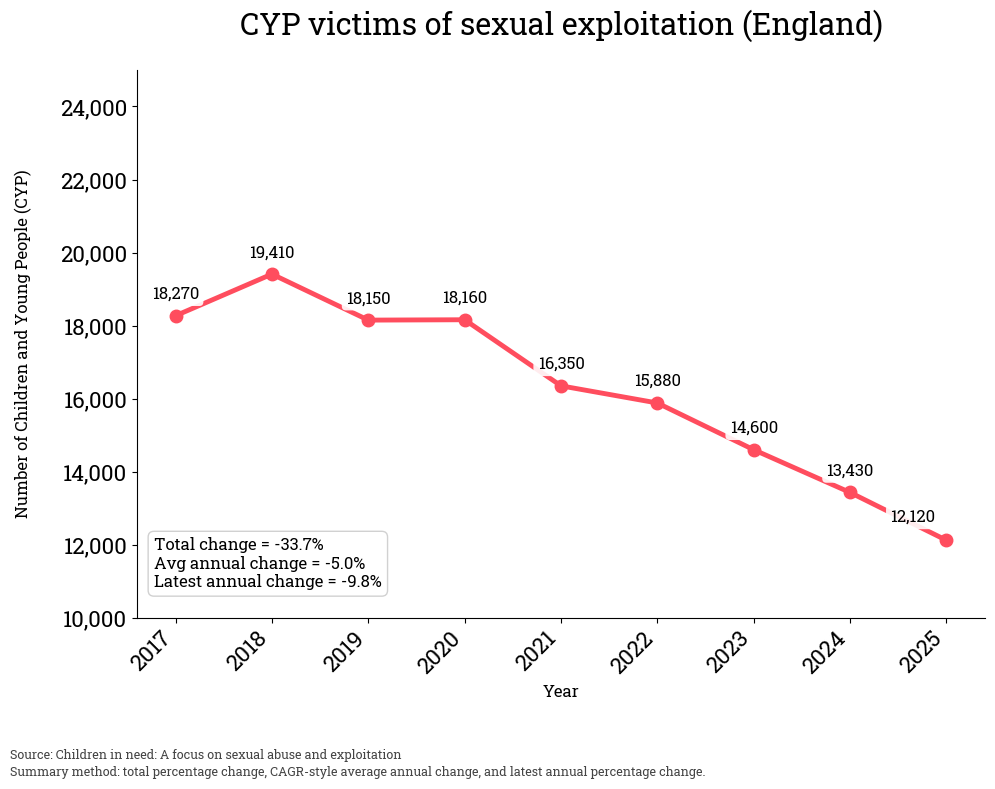

In [27]:
# Plotting indicators: Children victim of sexual abuse

plot_indicator(
    "CYPSPHVoM_9",
    df=df,
    title="CYP victims of sexual exploitation (England)",
    figsize=(10, 8),
    save_path="CYPSPHVoM_9.png"
)


Summary calculations for CYPSPHVoM_7: CYP who experienced victimisation in the last year (all types of crime)
Period: 2017/18 to 2023/24
Observations: 5

Start-to-end change
--------------------------------------------------------------------------------
Start value: 391,000
End value: 459,000
Absolute change: 68,000
Total percentage change: 17.4%
Average annual change (CAGR-style): 2.71% per year

Latest annual change
--------------------------------------------------------------------------------
Previous value: 434,000
Latest annual percentage change: +5.8%



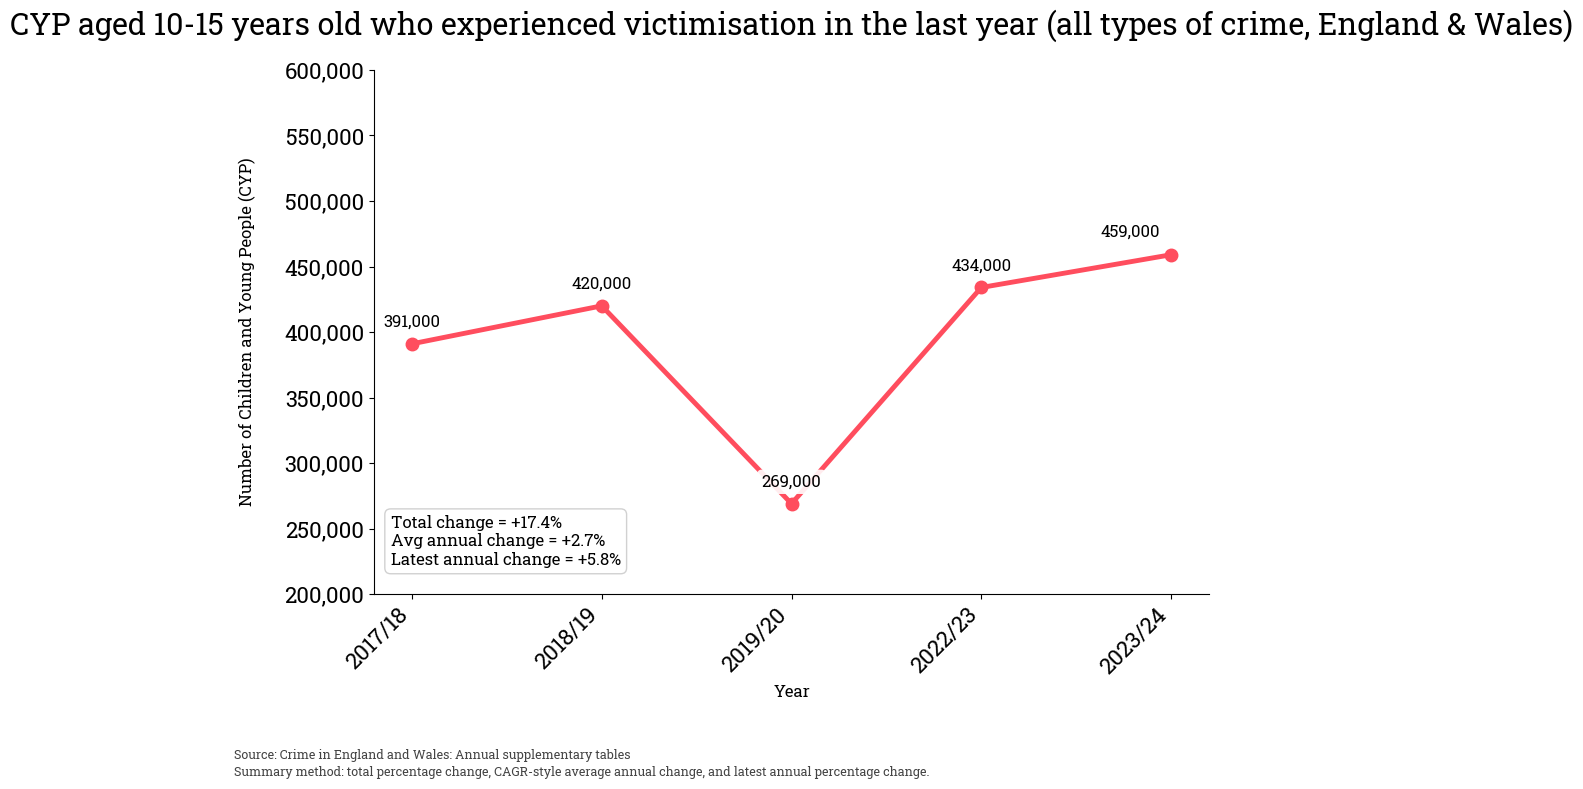

In [28]:
# Plotting indicators: children experiecing victimisation

plot_indicator(
    "CYPSPHVoM_7",
    year_filter=["201718", "201819", "201920", "202223", "202324"],
    df=df,
    title="CYP aged 10-15 years old who experienced victimisation in the last year (all types of crime, England & Wales)",
    figsize=(10, 8),
    save_path="CYPSPHVoM_7.png"
)


Summary calculations for CYPACTORIOHMISS_1: CYP reported missing during the year
Period: 2021 to 2025
Observations: 5

Start-to-end change
--------------------------------------------------------------------------------
Start value: 10,910
End value: 12,720
Absolute change: 1,810
Total percentage change: 16.6%
Average annual change (CAGR-style): 3.91% per year

Latest annual change
--------------------------------------------------------------------------------
Previous value: 13,000
Latest annual percentage change: -2.2%



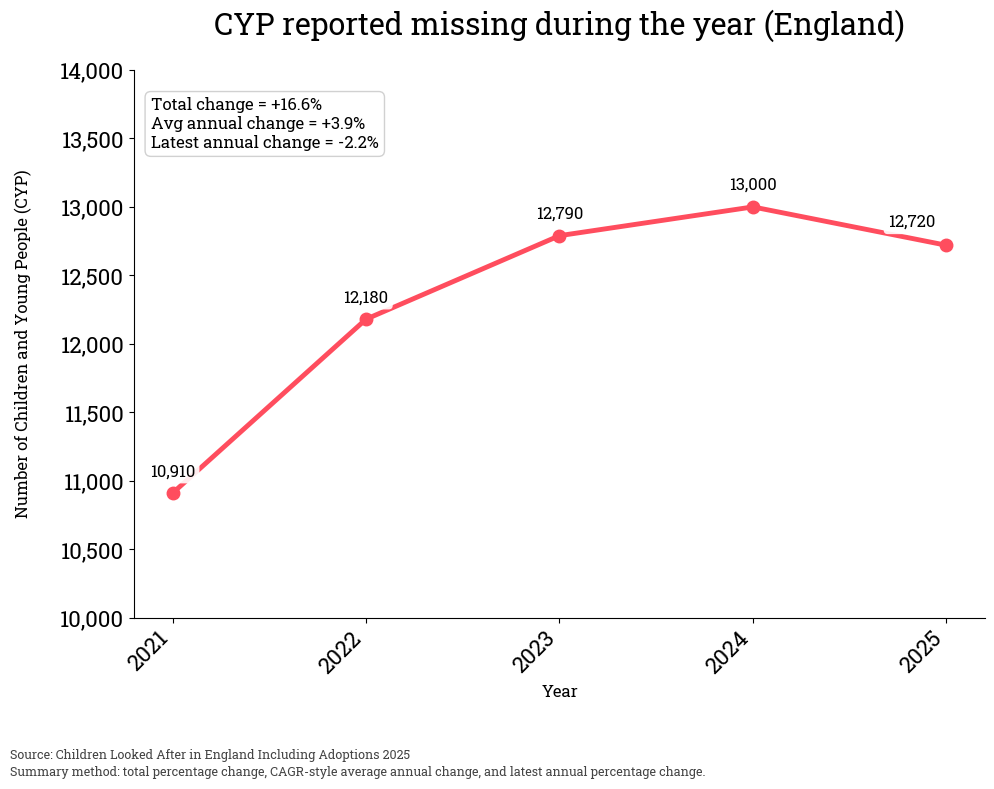

In [29]:
# Plotting indicators: Children who are Victim of Crime, Exploitation, Violence and Abuse

plot_indicator(
    "CYPACTORIOHMISS_1",
    df=df,
    title="CYP reported missing during the year (England)",
    figsize=(10, 8),
    save_path="CYPACTORIOHMISS_1.png"
)

# Plotting indicators: Children in the Secure Estate


Summary calculations for CYPACTORIOHCJS_2: CYP who are first time entrants to the youth justice system
Period: 2018 to 2024
Observations: 7

Start-to-end change
--------------------------------------------------------------------------------
Start value: 12,732
End value: 8,110
Absolute change: -4,622
Total percentage change: -36.3%
Average annual change (CAGR-style): -7.24% per year

Latest annual change
--------------------------------------------------------------------------------
Previous value: 8,430
Latest annual percentage change: -3.8%



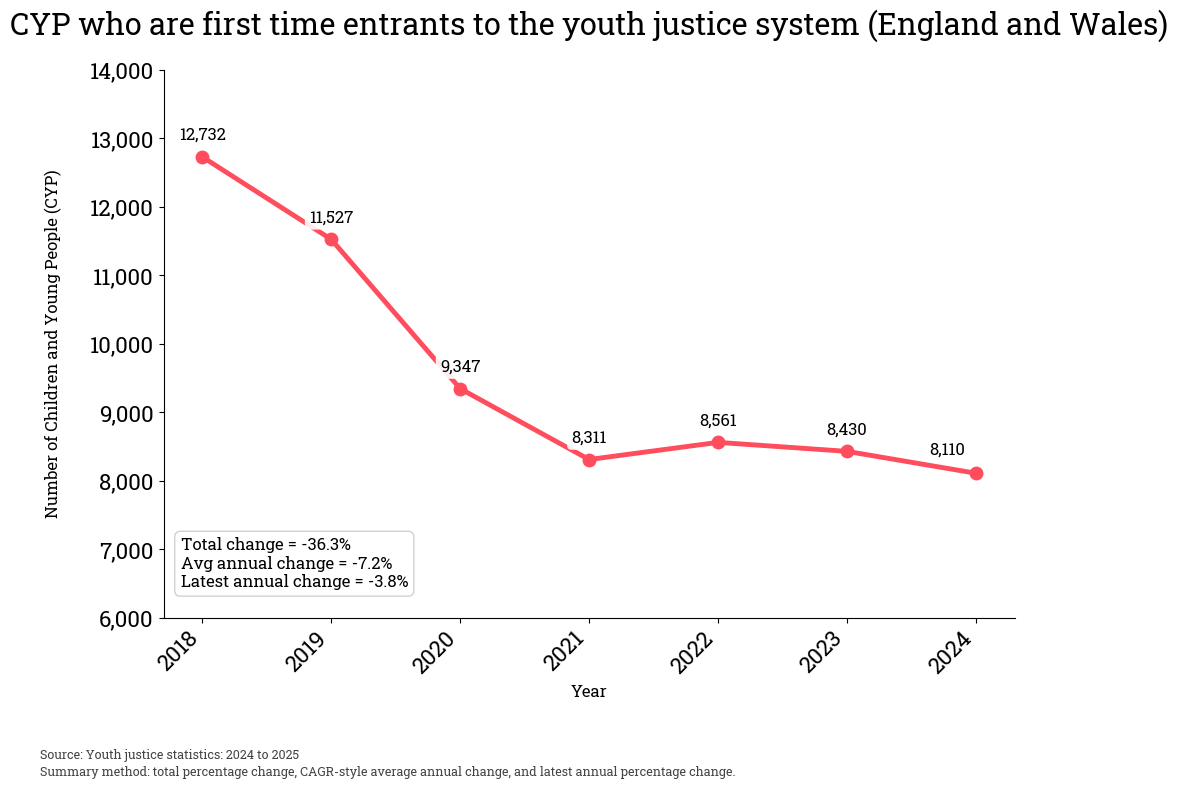

In [30]:
## CYP who are first time entrants to the youth justice system

plot_indicator(
    "CYPACTORIOHCJS_2",
    df=df,
    title="CYP who are first time entrants to the youth justice system (England and Wales)",
    figsize=(10, 8),
    save_path="CYPACTORIOHCJS_2.png"
)


Summary calculations for CYPACTORIOHCJS_1: Sentencing occasions of children
Period: 2017 to 2025
Observations: 9

Start-to-end change
--------------------------------------------------------------------------------
Start value: 1,607
End value: 613
Absolute change: -994
Total percentage change: -61.9%
Average annual change (CAGR-style): -11.35% per year

Latest annual change
--------------------------------------------------------------------------------
Previous value: 659
Latest annual percentage change: -7.0%



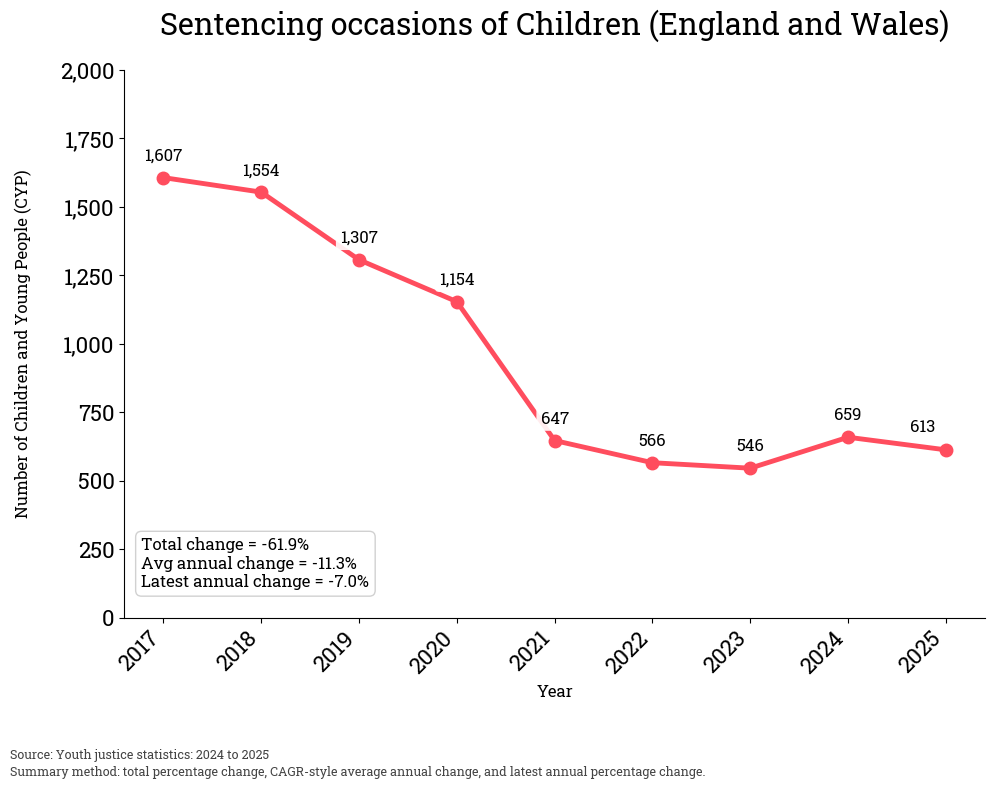

In [31]:
# Plotting indicators: Youth sentences

plot_indicator(
    "CYPACTORIOHCJS_1",
    df=df,
    title="Sentencing occasions of Children (England and Wales)",
    figsize=(10, 8),
    save_path="CYPACTORIOHCJS_1.png"
)


Summary calculations for CYPACTORIOHCJS_3: CYP who are reoffenders
Period: 2018 to 2024
Observations: 7

Start-to-end change
--------------------------------------------------------------------------------
Start value: 10,906
End value: 4,614
Absolute change: -6,292
Total percentage change: -57.7%
Average annual change (CAGR-style): -13.36% per year

Latest annual change
--------------------------------------------------------------------------------
Previous value: 4,649
Latest annual percentage change: -0.8%



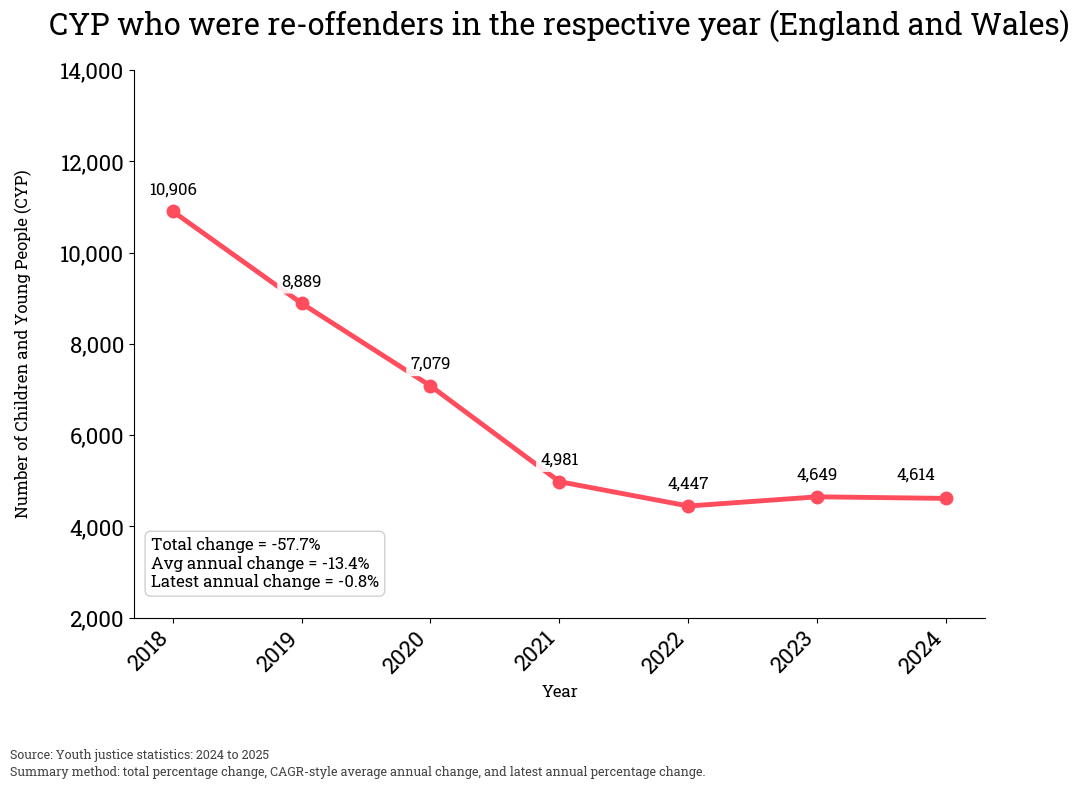

In [32]:
# CYP who are reoffenders

plot_indicator(
    "CYPACTORIOHCJS_3",
    df=df,
    title="CYP who were re-offenders in the respective year (England and Wales)",
    figsize=(10, 8),
    save_path="CYPACTORIOHCJS_3.png"
)


Summary calculations for CYPSCLA_11: CYP who were subject to a deprivation of liberty application
Period: 2023 to 2025
Observations: 3

Start-to-end change
--------------------------------------------------------------------------------
Start value: 651
End value: 1,439
Absolute change: 788
Total percentage change: 121.0%
Average annual change (CAGR-style): 48.68% per year

Latest annual change
--------------------------------------------------------------------------------
Previous value: 1,280
Latest annual percentage change: +12.4%



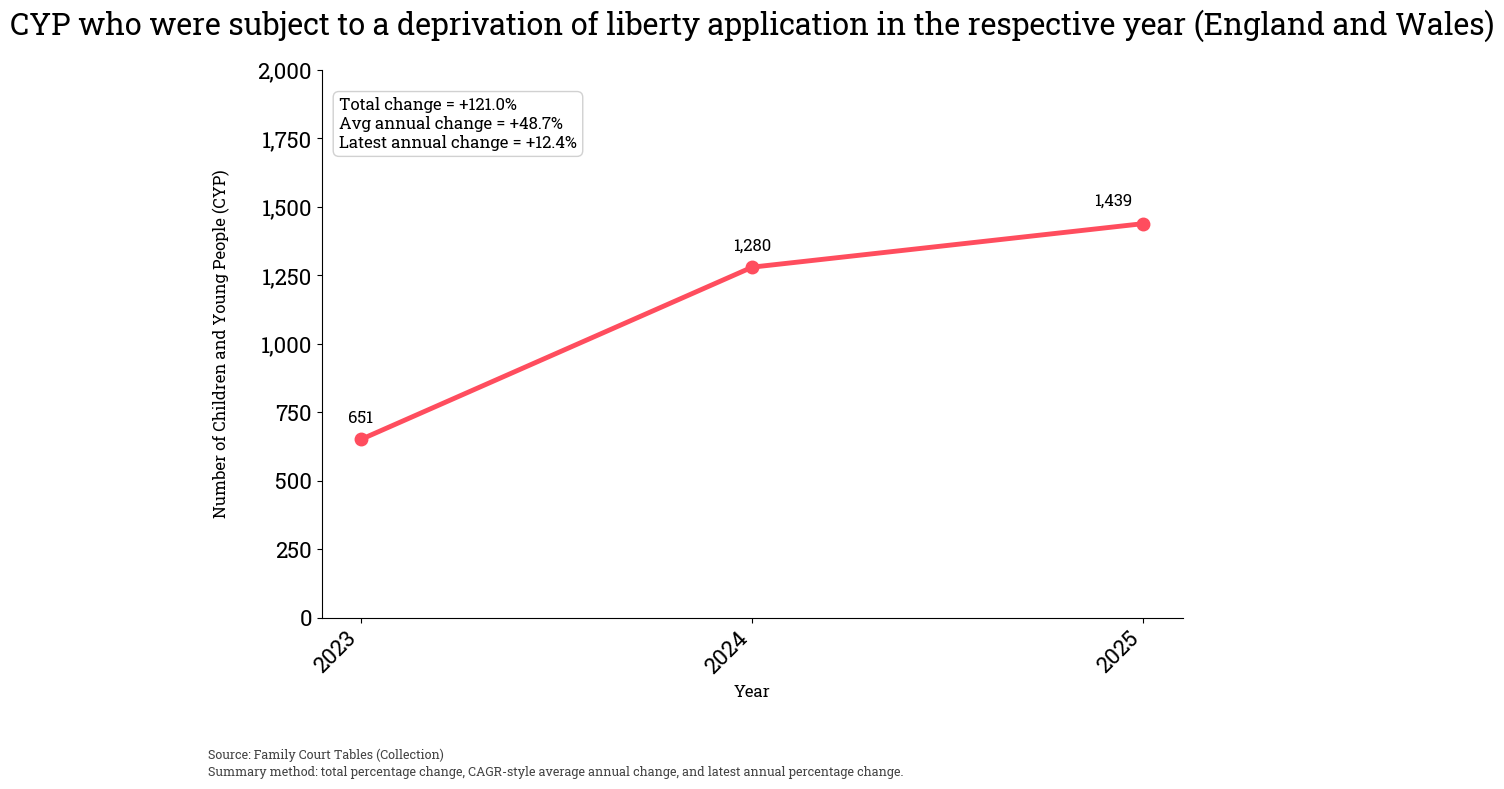

In [33]:
# CYP who were subject to a deprivation of liberty application in the respective year

plot_indicator(
    "CYPSCLA_11",
    df=df,
    title="CYP who were subject to a deprivation of liberty application in the respective year (England and Wales)",
    figsize=(10, 8),
    save_path="CYPSCLA_11.png"
)

# Plotting indicators: Children losing learning


Summary calculations for CYPACTORIOHOME_3: CYP reported as missing from education during the year
Period: 2021/22 to 2024/25
Observations: 4

Start-to-end change
--------------------------------------------------------------------------------
Start value: 94,900
End value: 143,500
Absolute change: 48,600
Total percentage change: 51.2%
Average annual change (CAGR-style): 14.78% per year

Latest annual change
--------------------------------------------------------------------------------
Previous value: 149,900
Latest annual percentage change: -4.3%



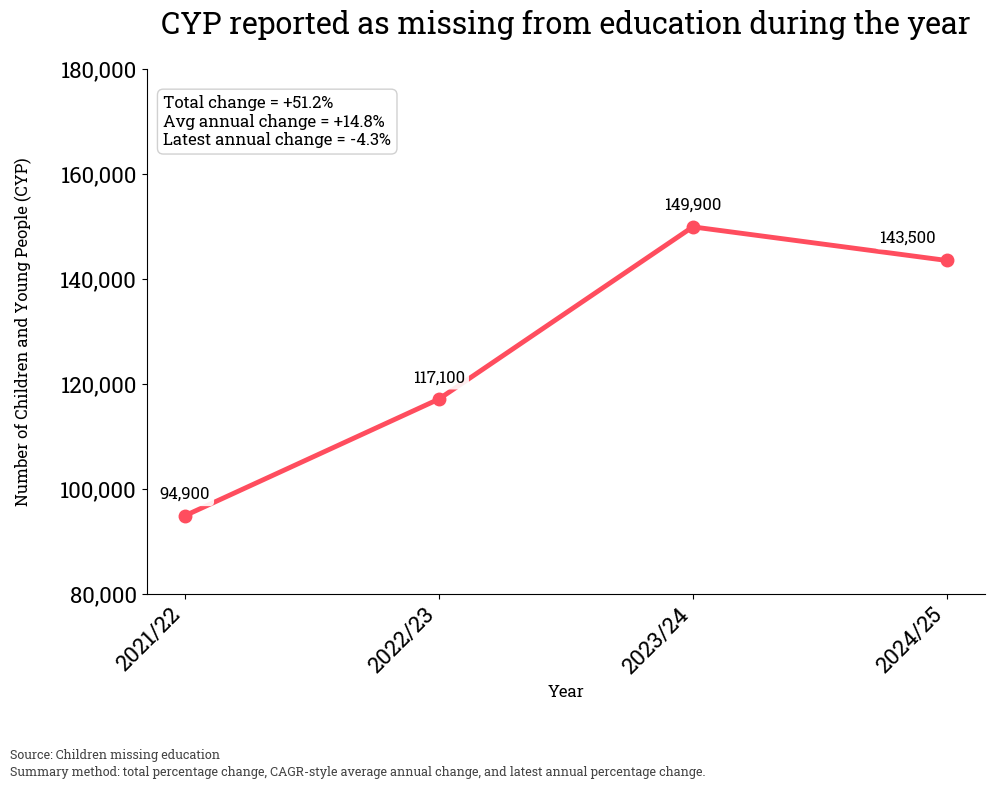

In [34]:
# Plotting indicators: CYP reported missing from education during the year

plot_indicator(
    "CYPACTORIOHOME_3",
    df=df,
    title="CYP reported as missing from education during the year",
    figsize=(10, 8),
    save_path="CYPACTORIOHOME_3.png"
)


Summary calculations for CYPACTORIOHOME_5: CYP who were persistent absentees
Period: 2017/18 to 2024/25
Observations: 7

Start-to-end change
--------------------------------------------------------------------------------
Start value: 783,424
End value: 1,340,437
Absolute change: 557,013
Total percentage change: 71.1%
Average annual change (CAGR-style): 7.97% per year

Latest annual change
--------------------------------------------------------------------------------
Previous value: 1,487,022
Latest annual percentage change: -9.9%



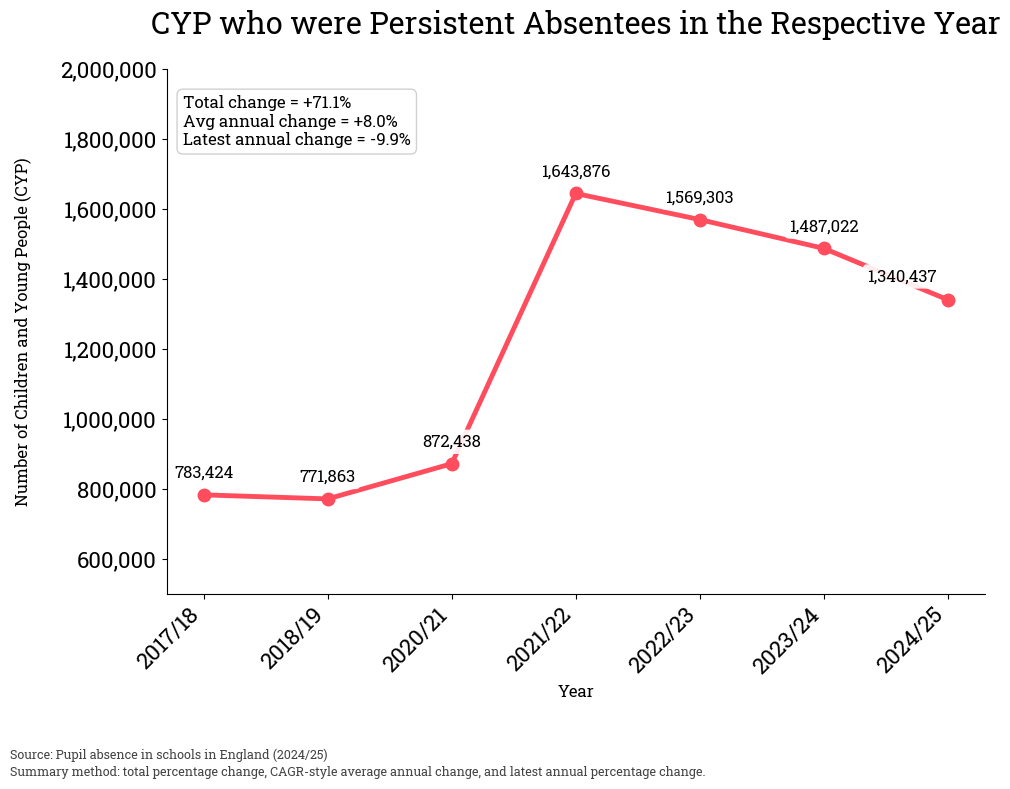

In [35]:
# Plotting indicators: Persistent Absence

plot_indicator(
    "CYPACTORIOHOME_5",
    df=df,
    title="CYP who were Persistent Absentees in the Respective Year",
    figsize=(10, 8),
    save_path="CYPACTORIOHOME_5.png"
)


Summary calculations for CYPACTORIOHOME_6: CYP who were severe absentees
Period: 2017/18 to 2024/25
Observations: 7

Start-to-end change
--------------------------------------------------------------------------------
Start value: 53,699
End value: 176,361
Absolute change: 122,662
Total percentage change: 228.4%
Average annual change (CAGR-style): 18.52% per year

Latest annual change
--------------------------------------------------------------------------------
Previous value: 171,269
Latest annual percentage change: +3.0%



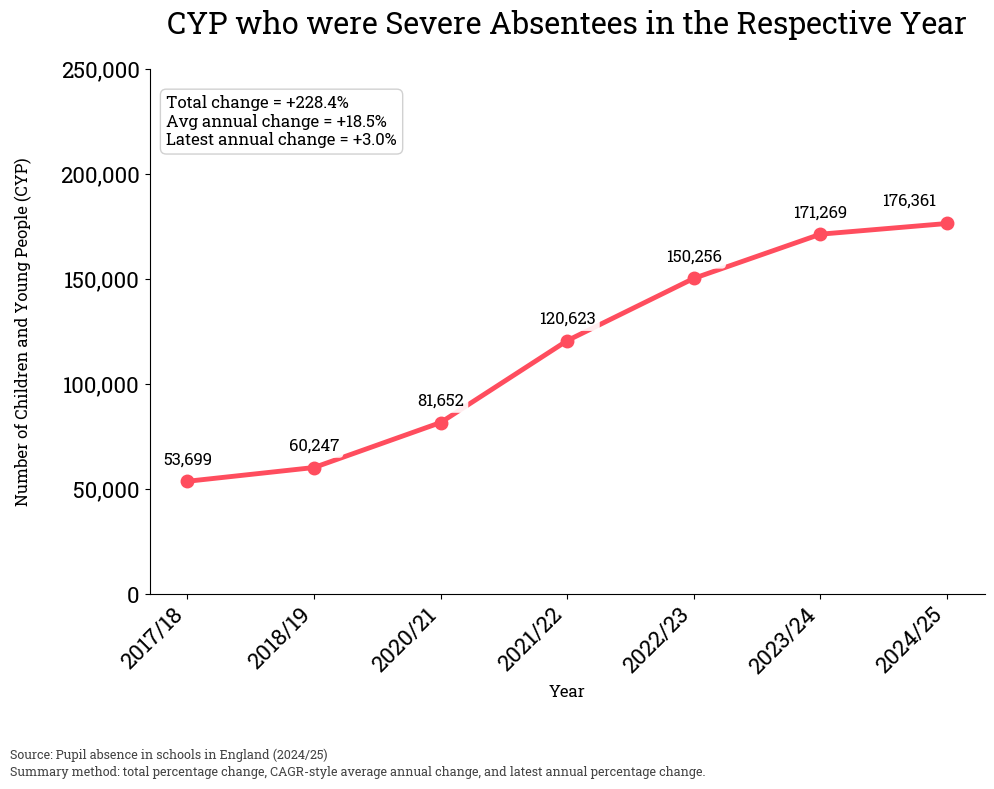

In [36]:
# Plotting indicators: Severe Absence

plot_indicator(
    "CYPACTORIOHOME_6",
    df=df,
    title="CYP who were Severe Absentees in the Respective Year",
    figsize=(10, 8),
    save_path="CYPACTORIOHOME_6.png"
)


Summary calculations for CYPACTORIOHOME_1: Pupil enrolments with one or more suspension
Period: 2019/20 to 2024/25
Observations: 6

Start-to-end change
--------------------------------------------------------------------------------
Start value: 104,342
End value: 165,649
Absolute change: 61,307
Total percentage change: 58.8%
Average annual change (CAGR-style): 9.68% per year

Latest annual change
--------------------------------------------------------------------------------
Previous value: 171,788
Latest annual percentage change: -3.6%



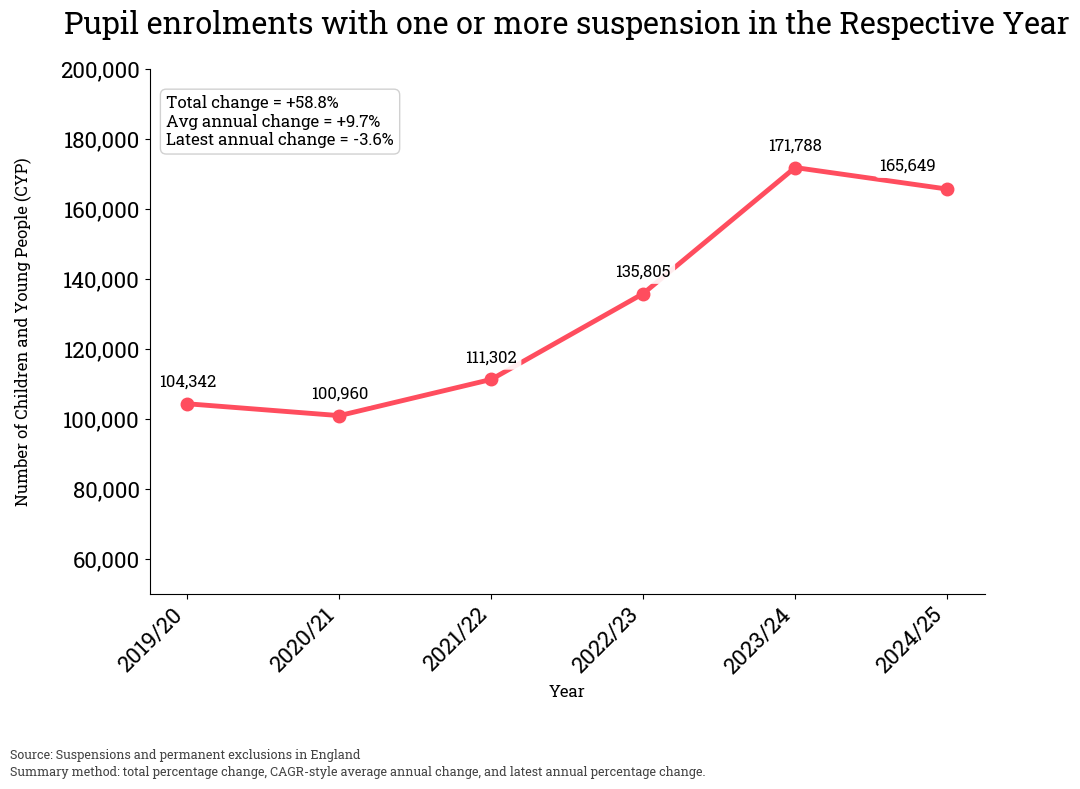

In [37]:
# Plotting indicators: Pupil enrolments with one or more suspension

plot_indicator(
    "CYPACTORIOHOME_1",
    df=df,
    title="Pupil enrolments with one or more suspension in the Respective Year",
    figsize=(10, 8),
    save_path="CYPACTORIOHOME_1.png"
)


Summary calculations for CYPACTORIOHOME_2: Pupils in LA Alternative Provision/Pupil referral units
Period: 2017/18 to 2024/25
Observations: 8

Start-to-end change
--------------------------------------------------------------------------------
Start value: 22,848
End value: 58,450
Absolute change: 35,602
Total percentage change: 155.8%
Average annual change (CAGR-style): 14.36% per year

Latest annual change
--------------------------------------------------------------------------------
Previous value: 47,612
Latest annual percentage change: +22.8%



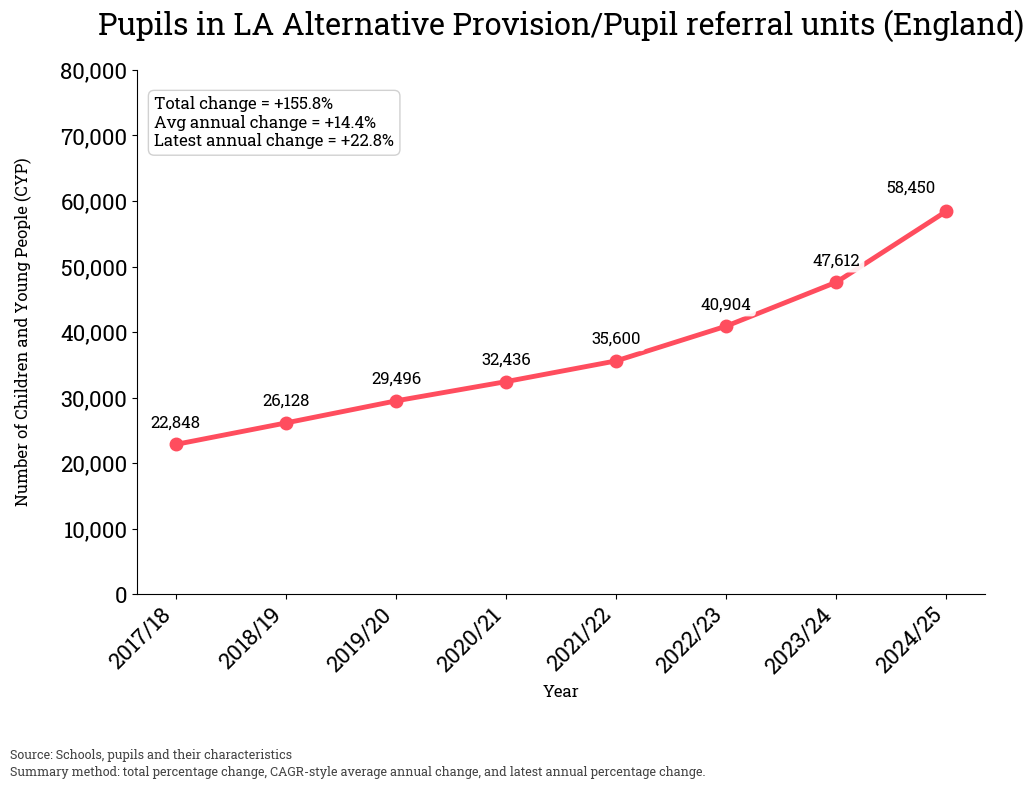

In [38]:
# Plotting indicators: LA Alternative Provision/Oupil Referral Units

plot_indicator(
    "CYPACTORIOHOME_2",
    df=df,
    title="Pupils in LA Alternative Provision/Pupil referral units (England)",
    figsize=(10, 8),
    save_path="CYPACTORIOHOME_2.png"
)


Summary calculations for CYPACTORIOHOME_4: CYP identified as NEET (Young People Not in Education, Employment or Training, aged 16-24)
Period: 2018 to 2025
Observations: 8

Start-to-end change
--------------------------------------------------------------------------------
Start value: 650,765
End value: 839,893
Absolute change: 189,129
Total percentage change: 29.1%
Average annual change (CAGR-style): 3.71% per year

Latest annual change
--------------------------------------------------------------------------------
Previous value: 836,955
Latest annual percentage change: +0.4%



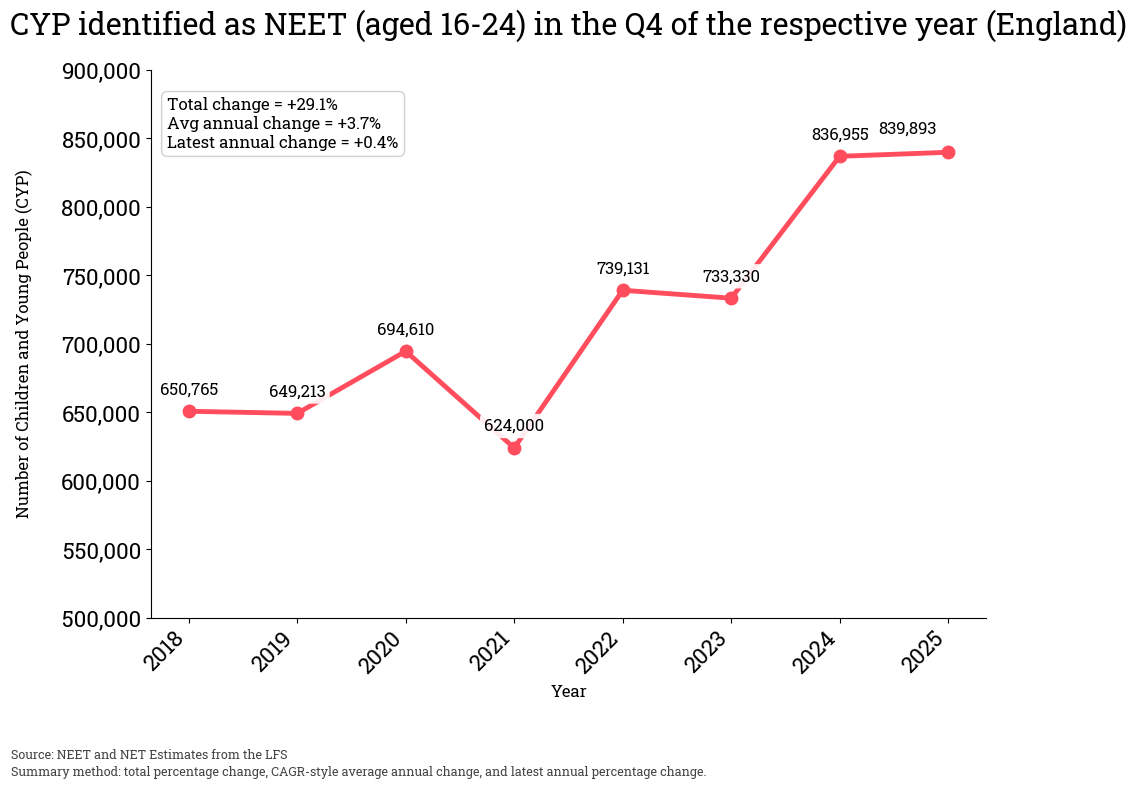

In [39]:
# Plotting indicators: CYP who are NEET

plot_indicator(
    "CYPACTORIOHOME_4",
    df=df,
    title="CYP identified as NEET (aged 16-24) in the Q4 of the respective year (England)",
    figsize=(10, 8),
    save_path="CYPACTORIOHOME_4.png"
)


Summary calculations for CYPACTORIOHOME_7: CYP who are electively home educated at any point in the academic year
Period: 2021/22 to 2024/25
Observations: 4

Start-to-end change
--------------------------------------------------------------------------------
Start value: 116,300
End value: 175,900
Absolute change: 59,600
Total percentage change: 51.2%
Average annual change (CAGR-style): 14.79% per year

Latest annual change
--------------------------------------------------------------------------------
Previous value: 153,300
Latest annual percentage change: +14.7%



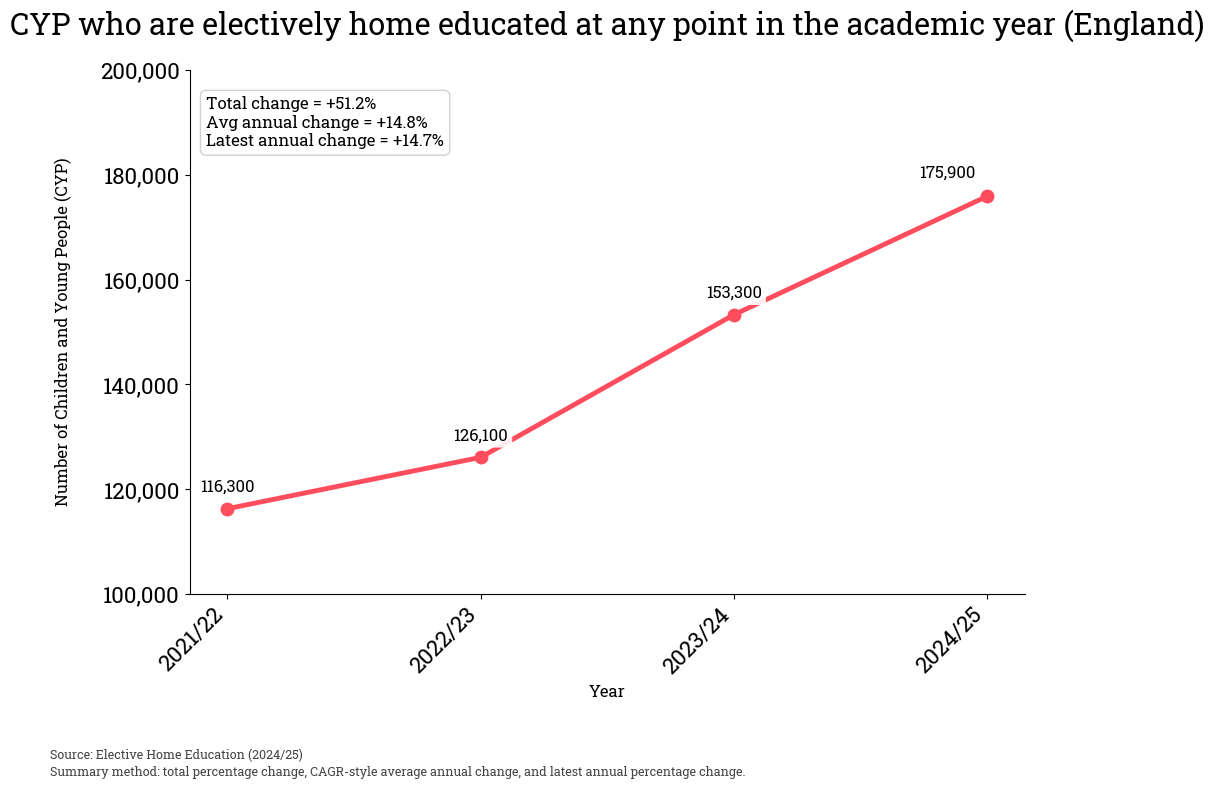

In [40]:
## number of CYP who were electively home educated at any point in time of the academic year

plot_indicator(
    "CYPACTORIOHOME_7",
    df=df,
    title="CYP who are electively home educated at any point in the academic year (England)",
    figsize=(10, 8),
    save_path="CYPACTORIOHOME_7.png"
)

## Children not reaching a Good Level of Development


Summary calculations for CYPDISAEYFS_1: CYP not reaching a Good Level of Development (GLD) in the year
Period: 2021/22 to 2024/25
Observations: 4

Start-to-end change
--------------------------------------------------------------------------------
Start value: 216,860
End value: 186,880
Absolute change: -29,980
Total percentage change: -13.8%
Average annual change (CAGR-style): -4.84% per year

Latest annual change
--------------------------------------------------------------------------------
Previous value: 196,591
Latest annual percentage change: -4.9%



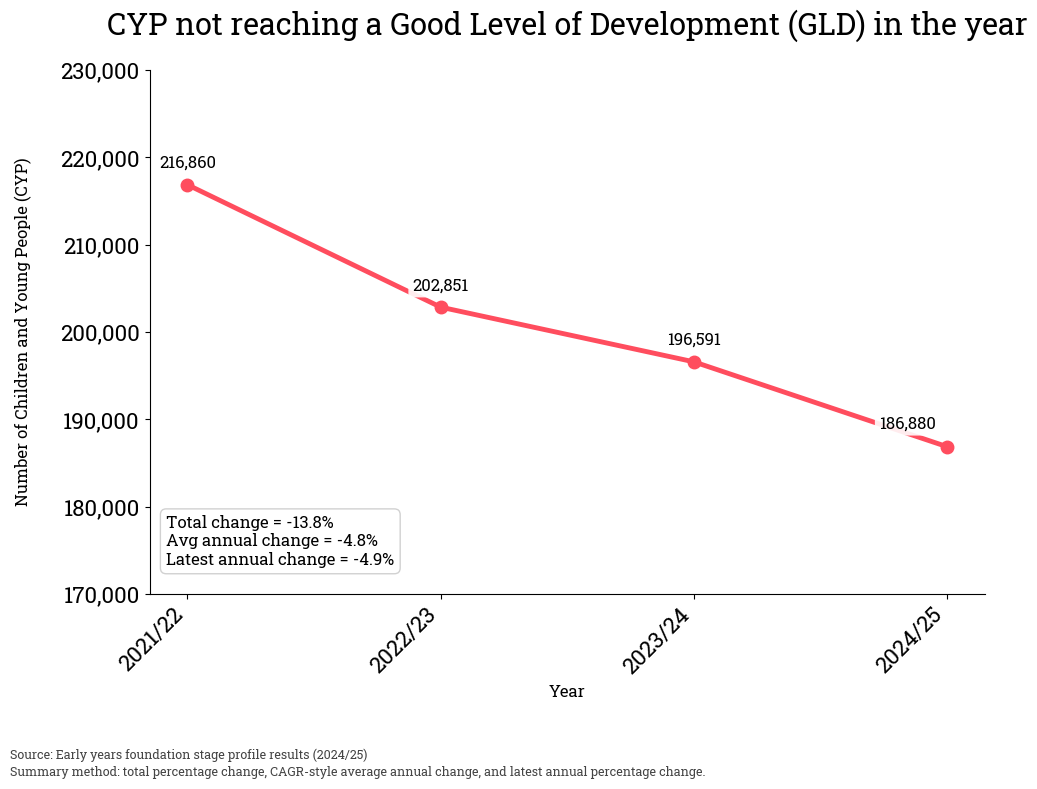

In [41]:
plot_indicator(
    "CYPDISAEYFS_1",
    df=df,
    title="CYP not reaching a Good Level of Development (GLD) in the year",
    figsize=(10, 8),
    save_path="CYPDISAEYFS_1.png"
)

## Special Education Needs


Summary calculations for CYPDISASEN_9: CYP with Special Education Needs (SEN)
Period: 2017/18 to 2024/25
Observations: 8

Start-to-end change
--------------------------------------------------------------------------------
Start value: 1,276,216
End value: 1,766,924
Absolute change: 490,708
Total percentage change: 38.5%
Average annual change (CAGR-style): 4.76% per year

Latest annual change
--------------------------------------------------------------------------------
Previous value: 1,673,205
Latest annual percentage change: +5.6%



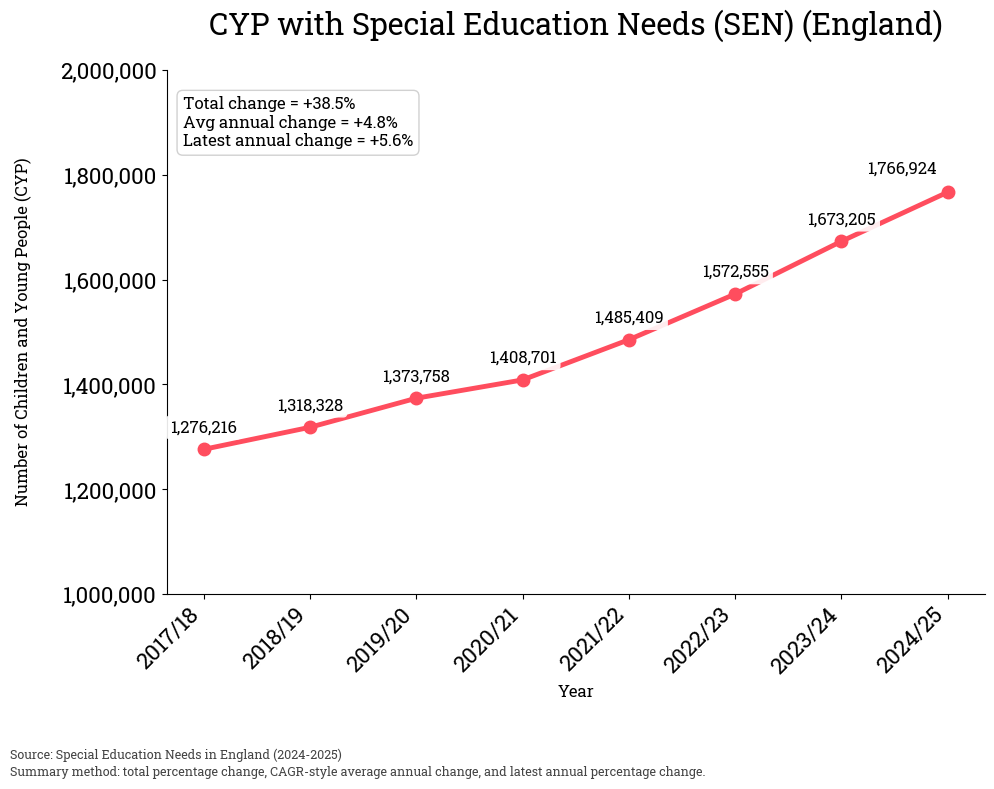

In [42]:
# Plotting indicators: Children with special education needs (SEN) -- TOTAL

plot_indicator(
    "CYPDISASEN_9",
    df=df,
    title="CYP with Special Education Needs (SEN) (England)",
    figsize=(10, 8),
    save_path="CYPDISASEN_9.png"
)


Summary calculations for CYPDISASEN_1: CYP with SEN support (without statements or EHC plans)
Period: 2017/18 to 2024/25
Observations: 8

Start-to-end change
--------------------------------------------------------------------------------
Start value: 1,022,537
End value: 1,284,284
Absolute change: 261,747
Total percentage change: 25.6%
Average annual change (CAGR-style): 3.31% per year

Latest annual change
--------------------------------------------------------------------------------
Previous value: 1,238,851
Latest annual percentage change: +3.7%



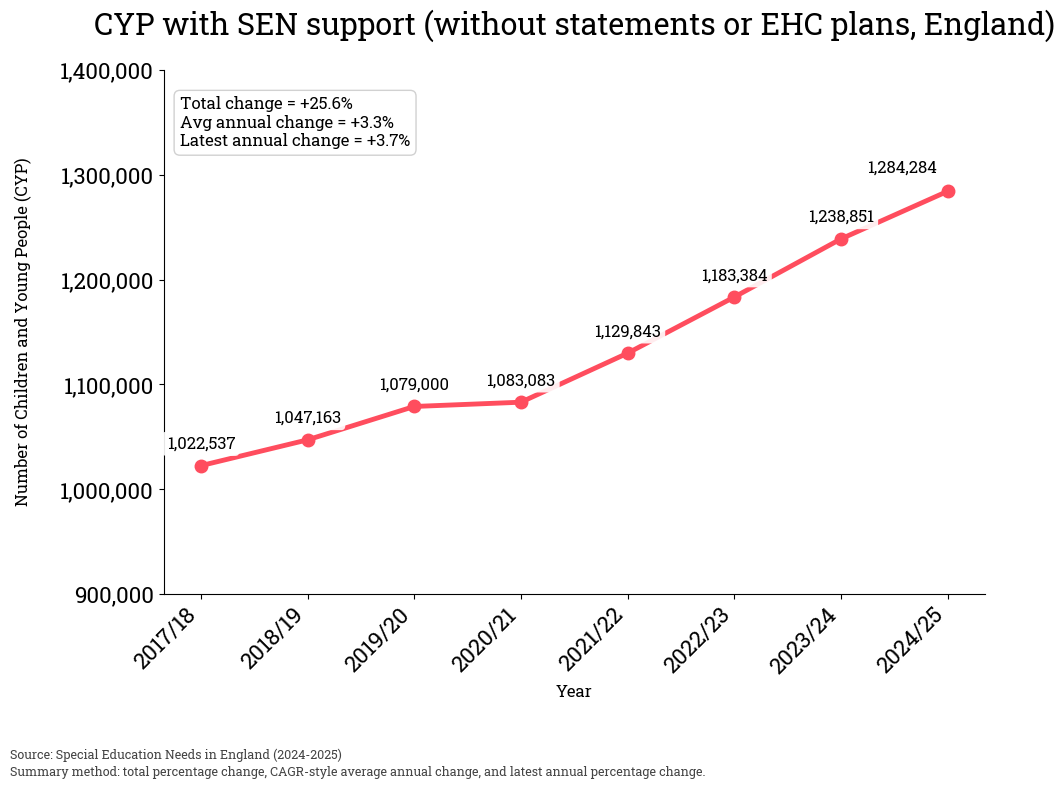

In [43]:
# Plotting indicators: Children with special education needs (SEN) -- SEN SUPPORT

plot_indicator(
    "CYPDISASEN_1",
    df=df,
    title="CYP with SEN support (without statements or EHC plans, England)",
    figsize=(10, 8),
    save_path="CYPDISASEN_1.png"
)


Summary calculations for CYPSCSEN: Pupils with statements or EHC plans
Period: 2017/18 to 2024/25
Observations: 8

Start-to-end change
--------------------------------------------------------------------------------
Start value: 253,679
End value: 482,640
Absolute change: 228,961
Total percentage change: 90.3%
Average annual change (CAGR-style): 9.62% per year

Latest annual change
--------------------------------------------------------------------------------
Previous value: 434,354
Latest annual percentage change: +11.1%



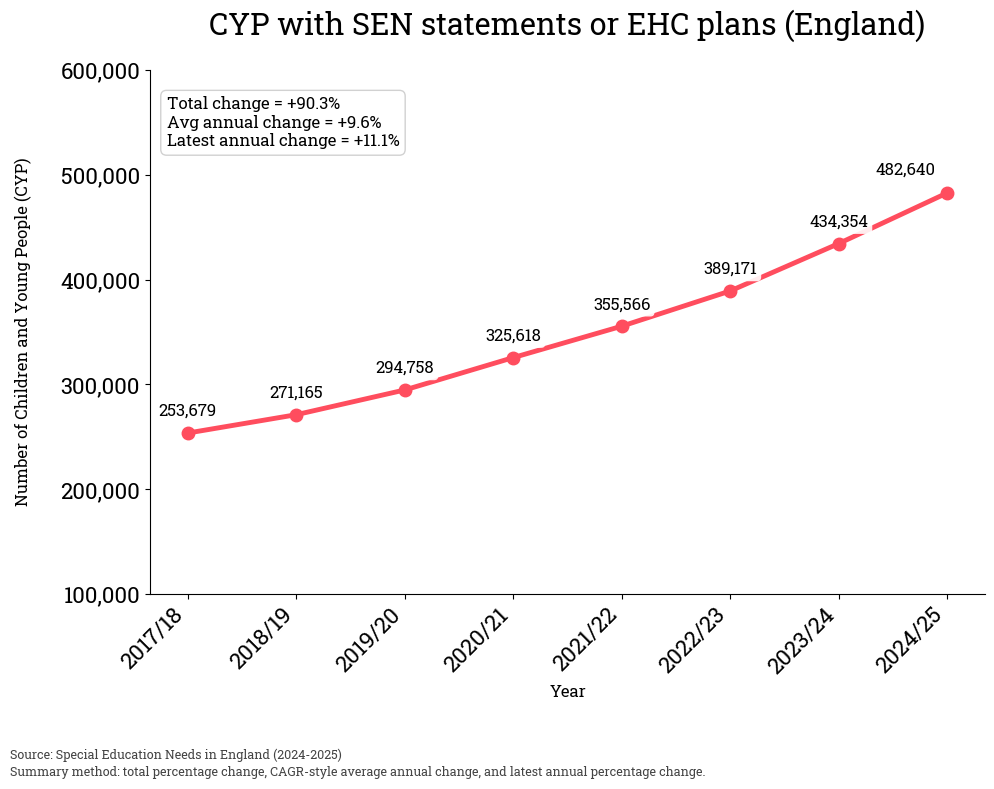

In [44]:
# Plotting indicators: Children with special education needs (SEN)

plot_indicator(
    "CYPSCSEN",
    df=df,
    title="CYP with SEN statements or EHC plans (England)",
    figsize=(10, 8),
    save_path="CYPSCSEN.png"
)



Summary calculations for CYPDISASEN_3: CYP with Autism Spectrum Disorder (ASD)
Period: 2017/18 to 2024/25
Observations: 8

Start-to-end change
--------------------------------------------------------------------------------
Start value: 120,992
End value: 263,989
Absolute change: 142,997
Total percentage change: 118.2%
Average annual change (CAGR-style): 11.79% per year

Latest annual change
--------------------------------------------------------------------------------
Previous value: 236,644
Latest annual percentage change: +11.6%



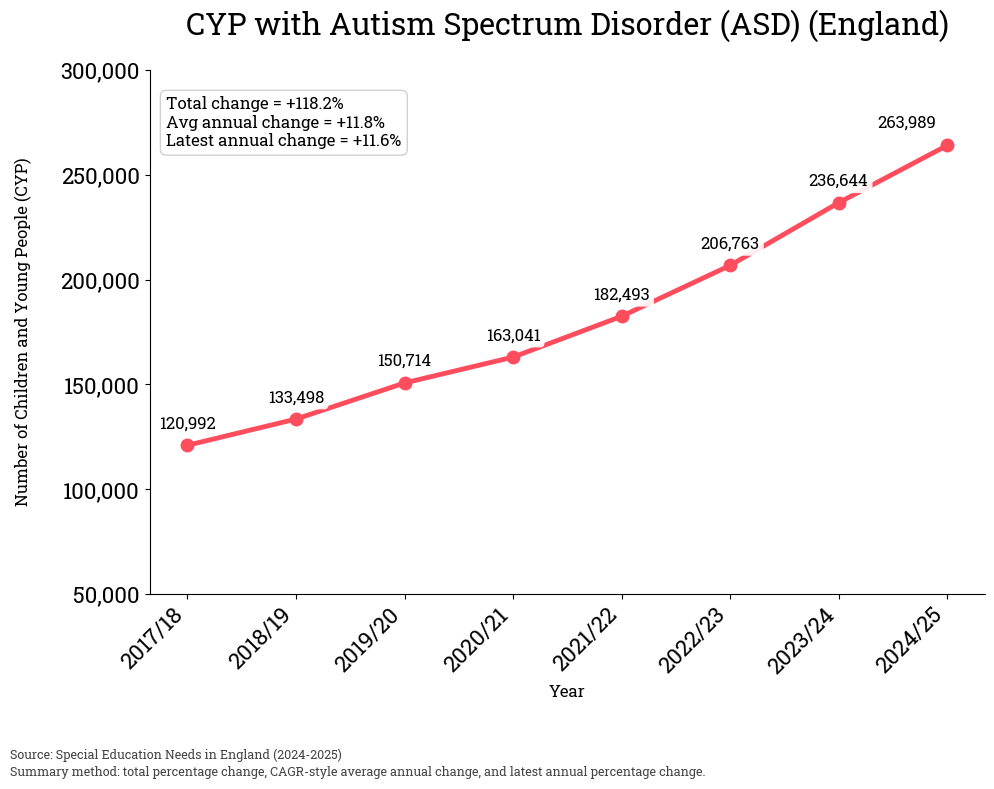

In [45]:
# Plotting indicators: Children with special education needs (SEN)

plot_indicator(
    "CYPDISASEN_3",
    df=df,
    title="CYP with Autism Spectrum Disorder (ASD) (England)",
    figsize=(10, 8),
    save_path="CYPDISASEN_3.png"
)

## Children with poor mental and physical health


Summary calculations for CYPDISAMH_1: CYP aged 8 to 16 with significant emotional and mental health issues
Period: 2017 to 2023
Observations: 10

Start-to-end change
--------------------------------------------------------------------------------
Start value: 12.5%
End value: 20.3%
Absolute change: +7.8 percentage points
Total percentage-point change: +7.8 percentage points
Average annual percentage-point change: +1.30 percentage points per year

Latest annual change
--------------------------------------------------------------------------------
Previous value: 20.3%
Latest annual percentage-point change: +0.0 pp



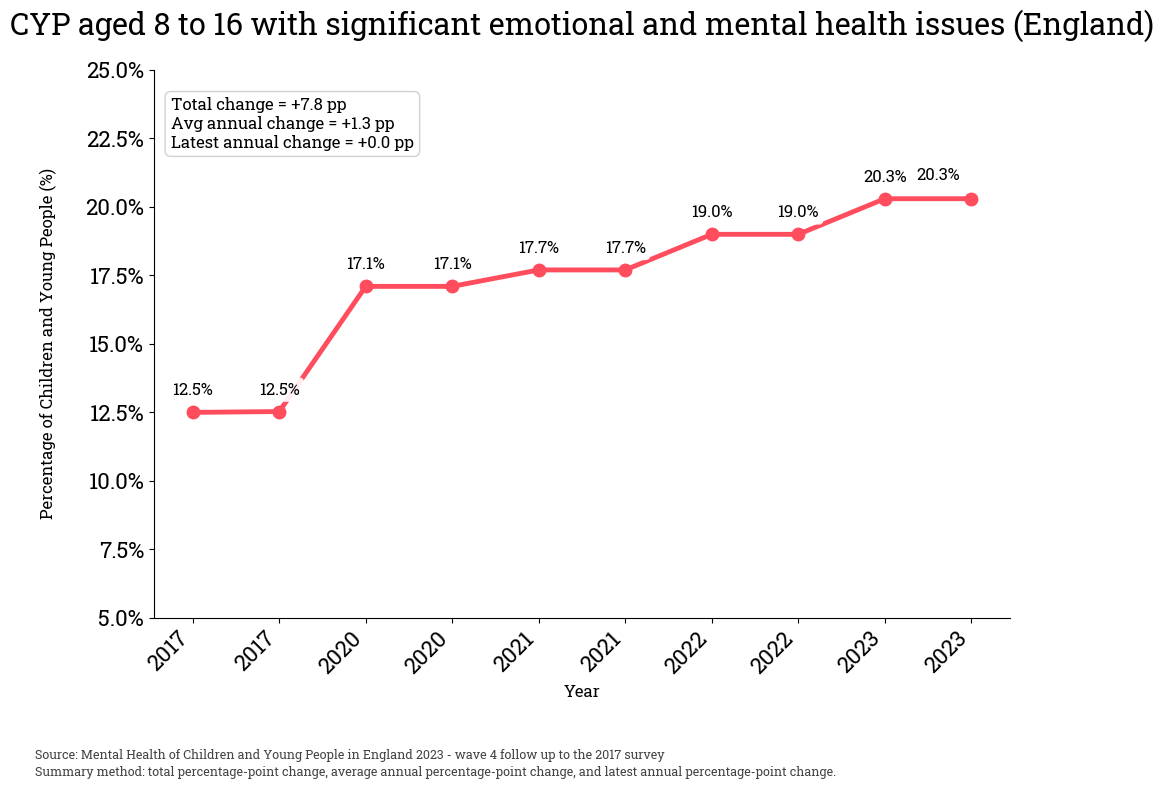

In [46]:
# Plotting indicators: Mental Health

plot_indicator(
    "CYPDISAMH_1",
    value_type="proportion",
    df=df,
    title="CYP aged 8 to 16 with significant emotional and mental health issues (England)",
    figsize=(10, 8),
    save_path="CYPDISAMH_1.png"
)



Summary calculations for CYPDISAUNHB_1: CYP who current vape
Period: 2014 to 2023
Observations: 5

Start-to-end change
--------------------------------------------------------------------------------
Start value: 21.9%
End value: 24.8%
Absolute change: +2.9 percentage points
Total percentage-point change: +2.9 percentage points
Average annual percentage-point change: +0.32 percentage points per year

Latest annual change
--------------------------------------------------------------------------------
Previous value: 22.1%
Latest annual percentage-point change: +2.8 pp



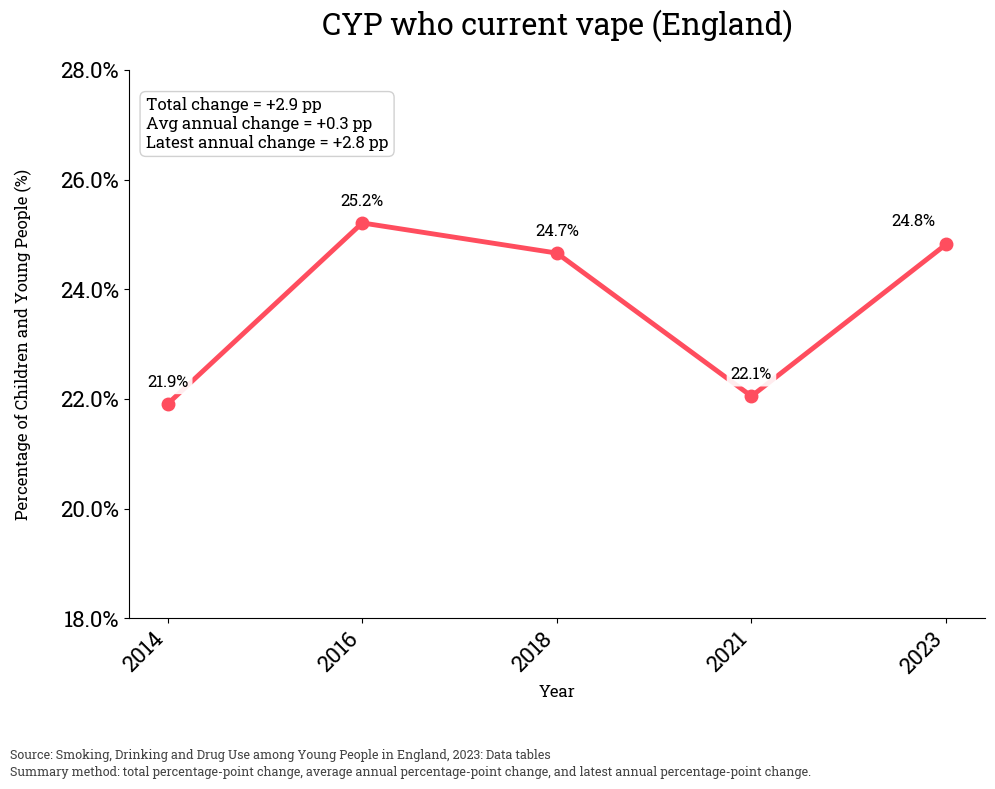

In [47]:
# Plotting indicators: Unhealthy Behaviours

plot_indicator(
    "CYPDISAUNHB_1",
    value_type="proportion",
    df=df,
    title="CYP who current vape (England)",
    figsize=(10, 8),
    save_path="CYPDISAUNHB_1.png"
)


Summary calculations for CYPDISACO_1: CYP who are obese (4 to 5 years)
Period: 2017/18 to 2024/25
Observations: 8

Start-to-end change
--------------------------------------------------------------------------------
Start value: 35,033
End value: 35,738
Absolute change: 705
Total percentage change: 2.0%
Average annual change (CAGR-style): 0.29% per year

Latest annual change
--------------------------------------------------------------------------------
Previous value: 33,440
Latest annual percentage change: +6.9%



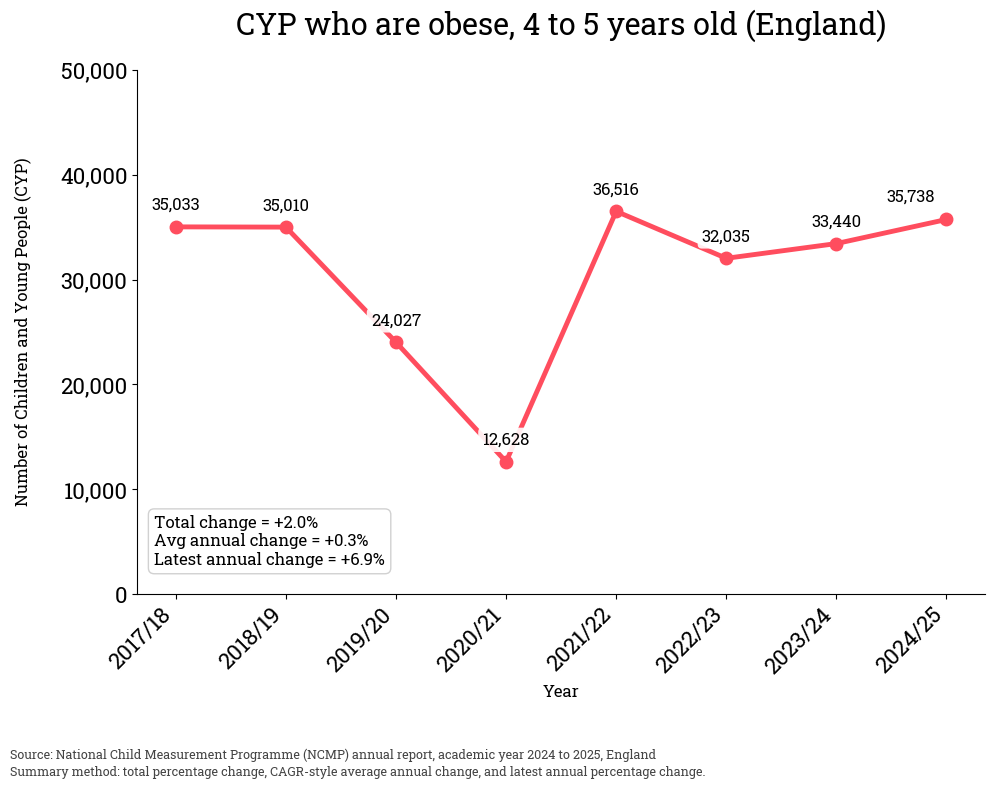

In [48]:
# Plotting indicators: Childhood Obesity

plot_indicator(
    "CYPDISACO_1",
    df=df,
    title="CYP who are obese, 4 to 5 years old (England)",
    figsize=(10, 8),
    save_path="CYPDISACO_1.png"
)


Summary calculations for CYPDISAPHY_4: CYP with tooth decay
Period: 2017 to 2025
Observations: 9

Start-to-end change
--------------------------------------------------------------------------------
Start value: 39,346
End value: 33,976
Absolute change: -5,370
Total percentage change: -13.6%
Average annual change (CAGR-style): -1.82% per year

Latest annual change
--------------------------------------------------------------------------------
Previous value: 30,587
Latest annual percentage change: +11.1%



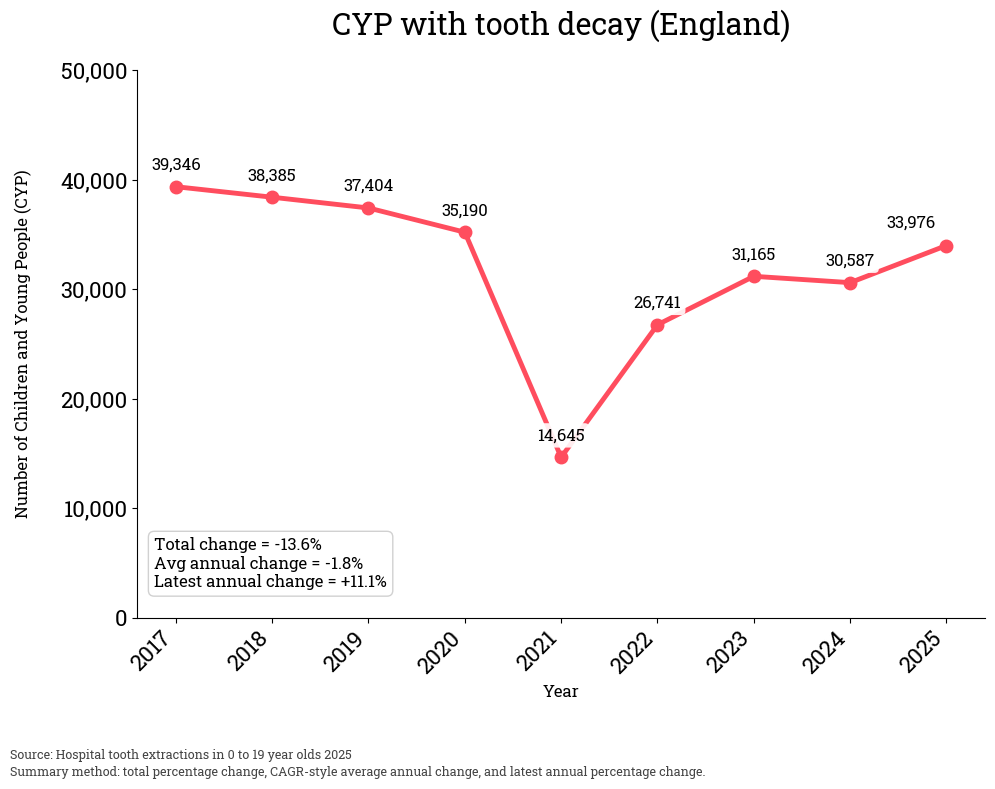

In [49]:
# Plotting indicators: tooth decay

plot_indicator(
    "CYPDISAPHY_4",
    df=df,
    title="CYP with tooth decay (England)",
    figsize=(10, 8),
    save_path="CYPDISAPHY_4.png"
)


Summary calculations for CYPDISACO_2: CYP who are obese (10 to 11 years)
Period: 2017/18 to 2024/25
Observations: 8

Start-to-end change
--------------------------------------------------------------------------------
Start value: 76,400
End value: 91,922
Absolute change: 15,522
Total percentage change: 20.3%
Average annual change (CAGR-style): 2.68% per year

Latest annual change
--------------------------------------------------------------------------------
Previous value: 92,139
Latest annual percentage change: -0.2%



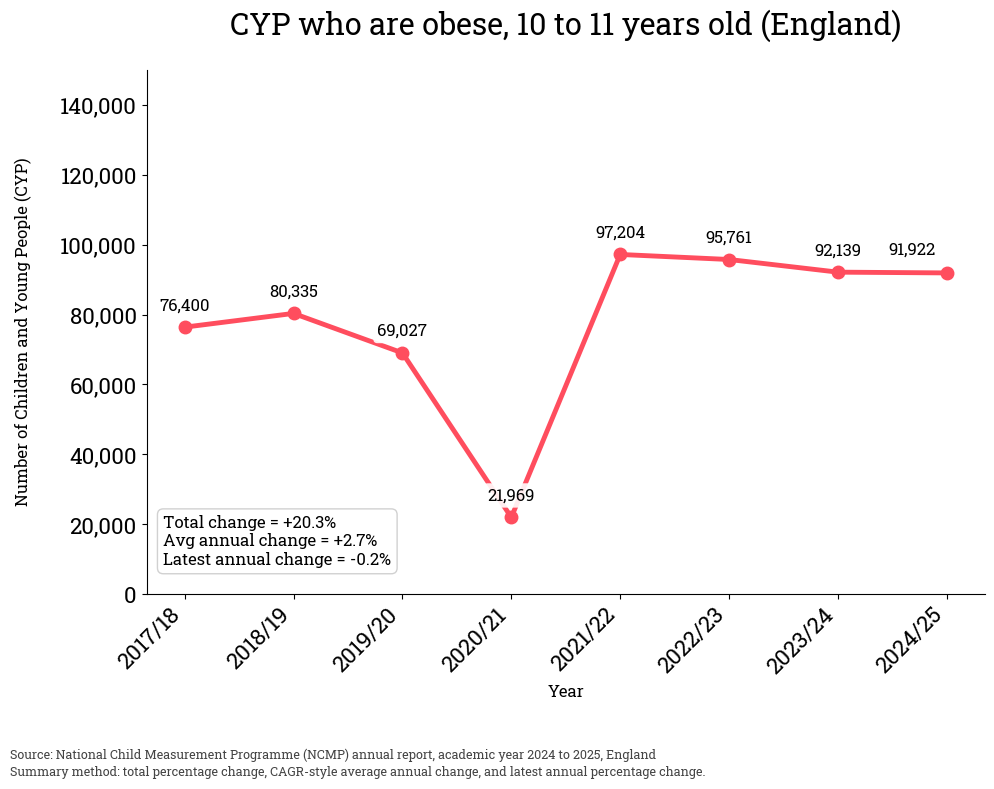

In [50]:
# Plotting indicators: Childhood Obesity

plot_indicator(
    "CYPDISACO_2",
    df=df,
    title="CYP who are obese, 10 to 11 years old (England)",
    figsize=(10, 8),
    save_path="CYPDISACO_2.png"
)


Summary calculations for CYPDISAPHY_1: CYP with a longstanding illness
Period: 2017 to 2024
Observations: 5

Start-to-end change
--------------------------------------------------------------------------------
Start value: 15.7%
End value: 18.1%
Absolute change: +2.4 percentage points
Total percentage-point change: +2.4 percentage points
Average annual percentage-point change: +0.34 percentage points per year

Latest annual change
--------------------------------------------------------------------------------
Previous value: 17.5%
Latest annual percentage-point change: +0.7 pp



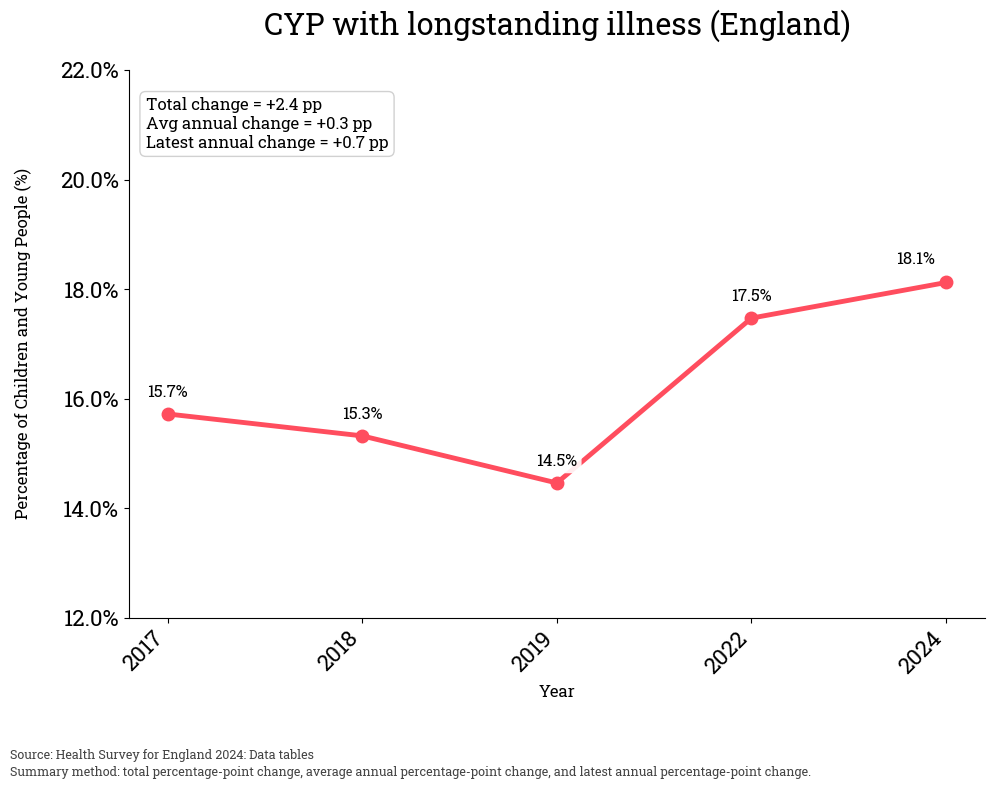

In [51]:
# Plotting indicators: Longstanding illness

plot_indicator(
    "CYPDISAPHY_1",
    value_type="proportion",
    df=df,
    title="CYP with longstanding illness (England)",
    figsize=(10, 8),
    save_path="CYPDISAPHY_1.png"
)


Summary calculations for CYPDISAPhI_1: A&E Attendances (0-4 years)
Period: 2021/22 to 2024/25
Observations: 4

Start-to-end change
--------------------------------------------------------------------------------
Start value: 2,332,838
End value: 2,418,515
Absolute change: 85,677
Total percentage change: 3.7%
Average annual change (CAGR-style): 1.21% per year

Latest annual change
--------------------------------------------------------------------------------
Previous value: 2,300,599
Latest annual percentage change: +5.1%



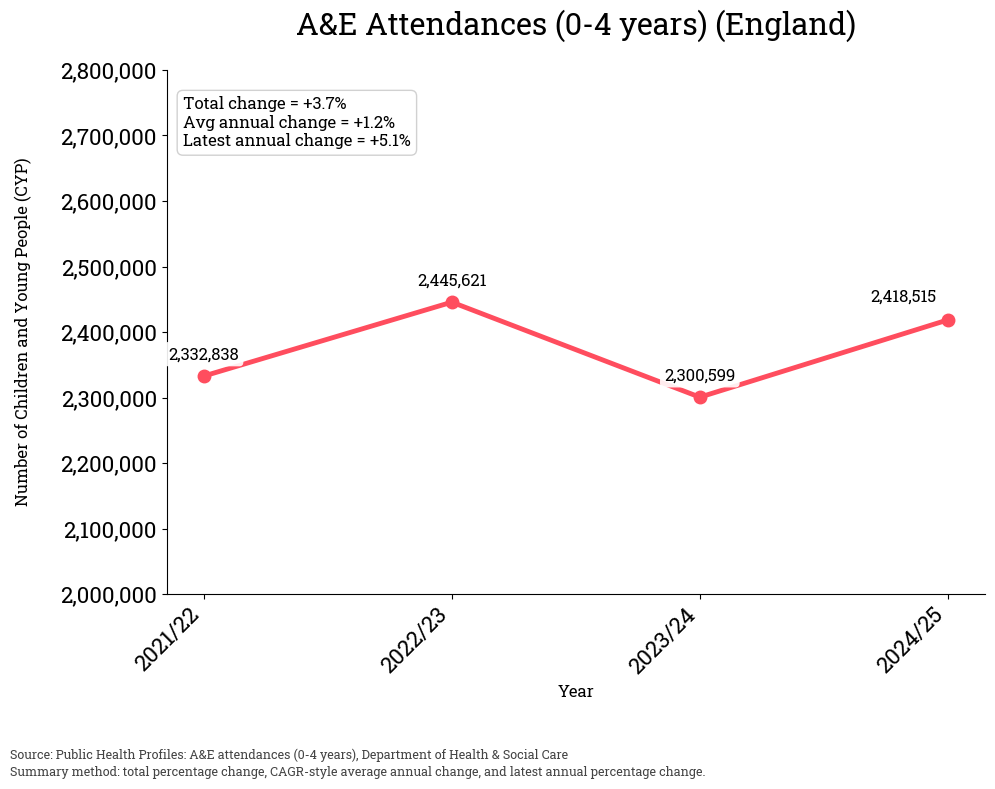

In [52]:
# Plotting indicators: A&E Attendances (0-4 years)

plot_indicator(
    "CYPDISAPhI_1",
    df=df,
    title="A&E Attendances (0-4 years) (England)",
    figsize=(10, 8),
    save_path="CYPDISAPhI_1.png"
)


Summary calculations for CYPDISAPhI_7: Child Death Rate aged 0-17 (per 1,000 people)
Period: 2020 to 2025
Observations: 6

Start-to-end change
--------------------------------------------------------------------------------
Start value: 29.0%
End value: 28.7%
Absolute change: -0.3 percentage points
Total percentage-point change: -0.3 percentage points
Average annual percentage-point change: -0.06 percentage points per year

Latest annual change
--------------------------------------------------------------------------------
Previous value: 29.8%
Latest annual percentage-point change: -1.1 pp



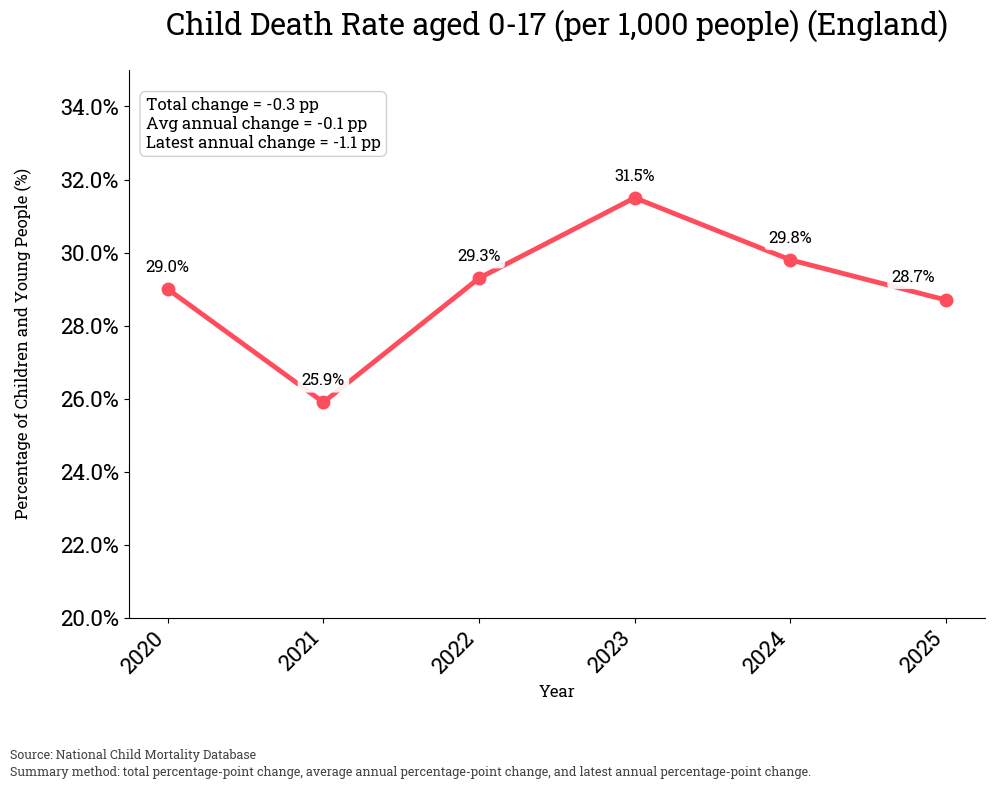

In [53]:
# Plotting indicators: Child Death Rate aged 0-17 (per 1,000 people)

plot_indicator(
    "CYPDISAPhI_7",
    value_type="proportion",
    df=df,
    title="Child Death Rate aged 0-17 (per 1,000 people) (England)",
    figsize=(10, 8),
    save_path="CYPDISAPhI_7.png"
)


Summary calculations for CYPDISAPhI_6: Child Death Notifications (0-17, year ending 31st of March)
Period: 2020 to 2025
Observations: 6

Start-to-end change
--------------------------------------------------------------------------------
Start value: 3,420
End value: 3,492
Absolute change: 72
Total percentage change: 2.1%
Average annual change (CAGR-style): 0.42% per year

Latest annual change
--------------------------------------------------------------------------------
Previous value: 3,577
Latest annual percentage change: -2.4%



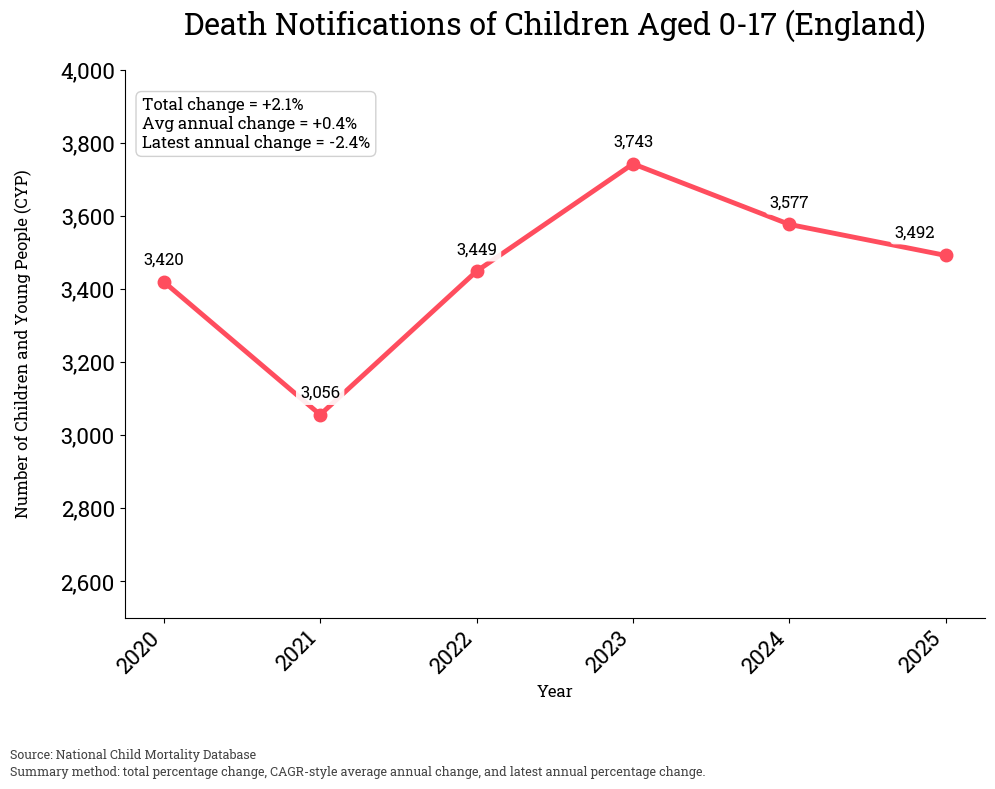

In [54]:
# Plotting indicators: Child Death Notifications aged 0-17

plot_indicator(
    "CYPDISAPhI_6",
    df=df,
    title="Death Notifications of Children Aged 0-17 (England)",
    figsize=(10, 8),
    save_path="CYPDISAPhI_6.png"
)

## Children from vulnerable migrant backgrounds


Summary calculations for CYPHPHARMIDENUIS_1: CYP who is Unaccompanied Asylum Seeker (UASC)
Period: 2017 to 2025
Observations: 9

Start-to-end change
--------------------------------------------------------------------------------
Start value: 4,710
End value: 6,540
Absolute change: 1,830
Total percentage change: 38.9%
Average annual change (CAGR-style): 4.19% per year

Latest annual change
--------------------------------------------------------------------------------
Previous value: 7,440
Latest annual percentage change: -12.1%



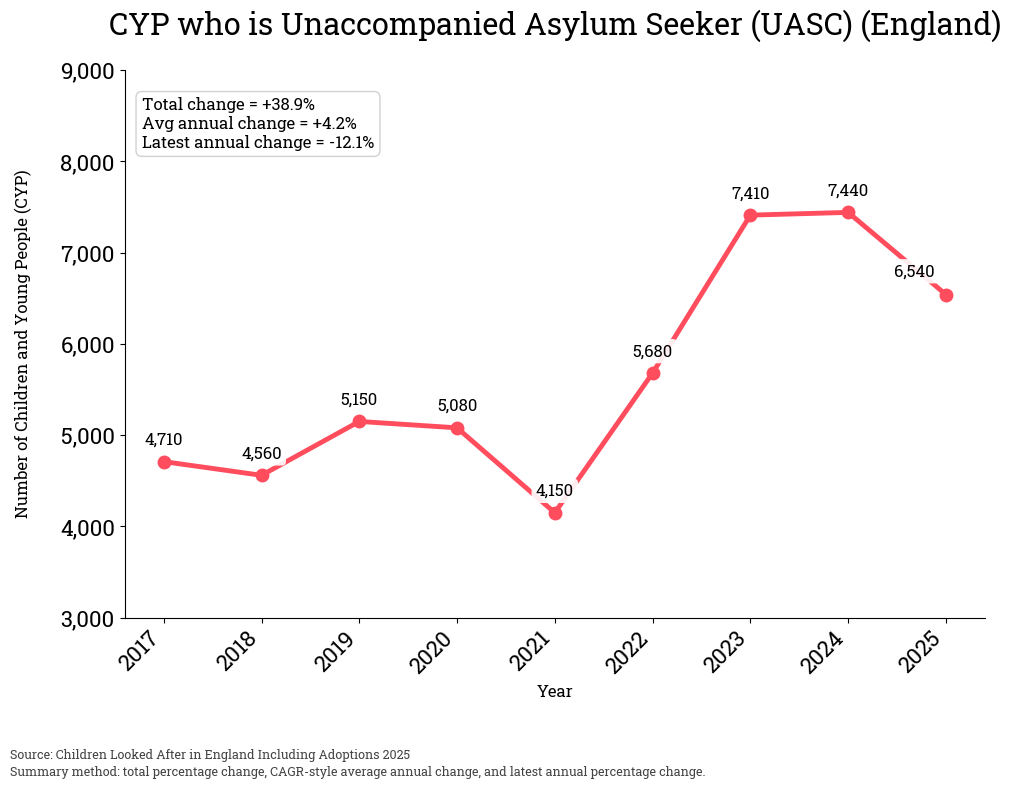

In [55]:
# Plotting indicators: Children from vulnerable migrant backgrounds

plot_indicator(
    "CYPHPHARMIDENUIS_1",
    source_id="CLA2025",
    df=df,
    title="CYP who is Unaccompanied Asylum Seeker (UASC) (England)",
    figsize=(10, 8),
    save_path="CYPHPHARMIDENUIS_1_CLA.png"
)


Summary calculations for CYPHPHARMIDENUIS_1: CYP who is Unaccompanied Asylum Seeker (UASC)
Period: 2017 to 2025
Observations: 9

Start-to-end change
--------------------------------------------------------------------------------
Start value: 2,399
End value: 3,598
Absolute change: 1,199
Total percentage change: 50.0%
Average annual change (CAGR-style): 5.20% per year

Latest annual change
--------------------------------------------------------------------------------
Previous value: 4,584
Latest annual percentage change: -21.5%



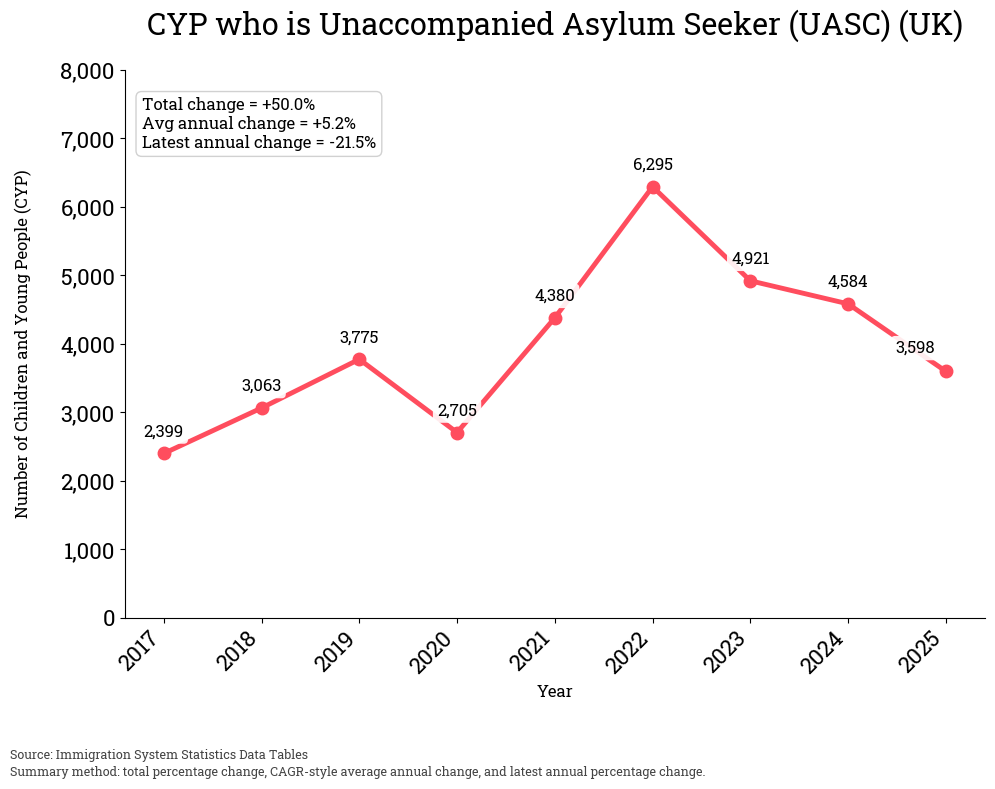

In [56]:
# Plotting indicators: Children from vulnerable migrant backgrounds

plot_indicator(
    "CYPHPHARMIDENUIS_1",
    source_id="IMMIGRATION2026",
    df=df,
    title="CYP who is Unaccompanied Asylum Seeker (UASC) (UK)",
    figsize=(10, 8),
    save_path="CYPHPHARMIDENUIS_1_HOME.png"
)